# Connect to google drive in colab

In [ ]:
from google.colab import drive
import os
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
src_path = "/content/drive/MyDrive/be3-computer-vision/competition_data.zip"
dst_path = "/content/"

# help me to unzip to : dst path if not exist
!unzip -q $src_path -d $dst_path

# if not os.path.exists(dst_path):
#     os.makedirs(dst_path)
#     !unzip -q "$src_path" -d "$dst_path"
#     print("Extraction completed.")
# else:
#     print("Files already extracted.")

# Install and Load Liberaries

In [ ]:
%%capture
!pip install torchmetrics

In [ ]:
import os
from PIL import Image
from torch.utils.data import Dataset
import torch
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import transforms
import matplotlib.pyplot as plt
import torch
import numpy as np
import random
import torch.nn as nn
import torch.nn.functional as F
from torchmetrics import Precision, Recall, F1Score, ConfusionMatrix
from IPython.display import clear_output
import time
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Seg Helpers

In [ ]:
MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

def denormalize(image):
    image = image.numpy().transpose(1, 2, 0)
    image = (image * STD) + MEAN
    image = np.clip(image, 0, 1)
    return image

def display_image_mask(image, mask):
    image = denormalize(image.cpu())
    mask = mask.squeeze(0).cpu().numpy()

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.title("Input Image")
    plt.imshow(image)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title("True Mask")
    plt.imshow(mask, cmap="gray")
    plt.axis('off')

    plt.show()

def display_image_true_pred_mask(image, true_mask, pred_mask):
    image = denormalize(image.cpu())
    true_mask = true_mask.squeeze(0).cpu().numpy()
    pred_mask = pred_mask.squeeze(0).cpu().numpy()

    # Display
    plt.figure(figsize=(15, 5))
    titles = ["Input Image", "True Mask", "Predicted Mask"]

    for i, img in enumerate([image, true_mask, pred_mask]):
        plt.subplot(1, 3, i + 1)
        plt.title(titles[i])
        plt.imshow(img if i == 0 else img, cmap="gray" if i > 0 else None)
        plt.axis("off")

    plt.show()

def compute_dataset_statistics(dataset, name="Dataset", num_classes=2):
    total_pixels = 0
    class_counts = np.zeros(num_classes, dtype=int)
    sum_channels = np.zeros(3)
    sum_squared_channels = np.zeros(3)

    for i in range(len(dataset)):
        image, mask = dataset[i]
        image = image.numpy()
        sum_channels += image.mean(axis=(1, 2))
        sum_squared_channels += (image ** 2).mean(axis=(1, 2))
        mask = mask.numpy().squeeze()
        if mask.max() > 1:
            mask = (mask > 127).astype(np.uint8)

        unique, counts = np.unique(mask, return_counts=True)
        for u, c in zip(unique, counts):
            if u < num_classes:
                class_counts[int(u)] += c
            else:
                print(f"Warning: unexpected mask value {u}.")
        total_pixels += mask.size

    mean_channels = sum_channels / len(dataset)
    std_channels = np.sqrt(sum_squared_channels / len(dataset) - mean_channels ** 2)

    print(f"\n📊 **{name} Statistics**")
    print(f"- Size: {len(dataset)} samples")
    print(f"- Mean per channel: {mean_channels}")
    print(f"- Std per channel: {std_channels}")
    print(f"- Min/Max pixel values in masks: (0, 1)")
    print("- Class distribution in masks:")
    for i in range(num_classes):
        percentage = (class_counts[i] / total_pixels) * 100 if total_pixels > 0 else 0
        print(f"  - Class {i}: {class_counts[i]} pixels ({percentage:.2f}%)")

# Load and Process Data

### Our Custom Dataset

In [ ]:
class SegDataset(Dataset):
    def __init__(self, data_dir, im_size, img_transform=None):
        self.image_dir = os.path.join(data_dir, "images")
        self.mask_dir = os.path.join(data_dir, "masks")
        self.image_names = os.listdir(self.image_dir)
        self.augmentation = img_transform

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, idx):
        # Load image
        image_name = self.image_names[idx]
        img_path = os.path.join(self.image_dir, image_name)
        image = np.array(Image.open(img_path).convert('RGB'))

        # Construct mask path.
        mask_name = os.path.splitext(image_name)[0] + '.png'
        mask_path = os.path.join(self.mask_dir, mask_name)
        mask = np.array(Image.open(mask_path).convert('L'))

        # transformations
        augmented = self.augmentation(image=image, mask=mask)
        image = augmented['image']
        mask = augmented['mask']

        # solving some issues
        if mask.max() > 1:
            mask = mask / 255.0

        if not isinstance(mask, torch.Tensor):
            mask = torch.tensor(mask, dtype=torch.float)
        else:
            mask = mask.float()

        if mask.ndim == 2:
            mask = mask.unsqueeze(0)

        return image, mask

### Create Train, Test and Validation Datasets

In [ ]:
# Data Parameters
b_size = 32
im_size = 128
data_dir = "/content/competition_data/train"
rand_seed = 42
num_workers = 1
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# Set the seed for reproducibility
torch.manual_seed(rand_seed)
np.random.seed(rand_seed)
random.seed(rand_seed)

# Define transformations
tr_transform = A.Compose([
    A.Resize(im_size, im_size),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=45, p=0.5),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2()
])

# test and validation transform
val_transform = A.Compose([
    A.Resize(im_size, im_size),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2()
])

# dataset
dataset = SegDataset(data_dir=data_dir, im_size=im_size, img_transform=tr_transform)

# calculate split
dataset_size = len(dataset)
test_size = int(0.1 * dataset_size)                     # 10%
valid_size = int(0.1 * dataset_size)                    # 10%
train_size = dataset_size - test_size - valid_size      # 80%

# apply the split
train_set, valid_set, test_set = random_split(
    dataset,
    [train_size, valid_size, test_size],
    generator=torch.Generator().manual_seed(rand_seed))

# disable augementation for test and valid data
test_set.dataset.img_transform = val_transform
valid_set.dataset.img_transform = val_transform

# Create DataLoaders
train_loader = DataLoader(train_set, batch_size=b_size, shuffle=True, num_workers=num_workers)
valid_loader = DataLoader(valid_set, batch_size=b_size, shuffle=True, num_workers=num_workers)
test_loader = DataLoader(test_set, batch_size=b_size, shuffle=True, num_workers=num_workers)

### Another Dataset I love To use is A tiny dataset for test of sanity check

In [ ]:
# Create a tiny subset for quick tests
tiny_subset = Subset(dataset, indices=np.random.choice(len(dataset), 10, replace=False))

# Create a tiny DataLoader
tiny_loader = DataLoader(tiny_subset, batch_size=b_size, shuffle=True, num_workers=num_workers)

### check loaders

In [ ]:
# Iterate through train dataloader
for batch_idx, (imgs, msks) in enumerate(valid_loader):
    print(f"Batch {batch_idx} - Images shape: {imgs.shape}, Masks shape: {msks.shape}")
    img = imgs[0]
    msk = msks[0]

    print(img.shape, msk.shape)
    # display_image_mask(img, msk)

    if batch_idx == 2:
        break

Batch 0 - Images shape: torch.Size([32, 3, 128, 128]), Masks shape: torch.Size([32, 1, 128, 128])
torch.Size([3, 128, 128]) torch.Size([1, 128, 128])
Batch 1 - Images shape: torch.Size([32, 3, 128, 128]), Masks shape: torch.Size([32, 1, 128, 128])
torch.Size([3, 128, 128]) torch.Size([1, 128, 128])
Batch 2 - Images shape: torch.Size([32, 3, 128, 128]), Masks shape: torch.Size([32, 1, 128, 128])
torch.Size([3, 128, 128]) torch.Size([1, 128, 128])


### i do this just to make sure randomness in splits is working

In [ ]:
# this function helps me to make sure the randomness in splitting is reproducable
compute_dataset_statistics(train_set, name="Train Dataset", num_classes=2)


📊 **Train Dataset Statistics**
- Size: 3200 samples
- Mean per channel: [-0.19885027 -0.0738314   0.14870892]
- Std per channel: [0.83380103 0.85242698 0.84863319]
- Min/Max pixel values in masks: (0, 1)
- Class distribution in masks:
  - Class 0: 40107937 pixels (76.50%)
  - Class 1: 12320863 pixels (23.50%)


# Build Model

### Model Helpers

> In the following section, I have defined some helpers that help me test all different architecture configurations for our model:

1. Max pooling
2. Skip Connections
3. FCN and Auto-encoder
4. Threshold for inference



In [ ]:
# =====================================#
#          helpers with cnn            #
# =====================================#
class D2Conv(nn.Module):
    def __init__(self, in_ch, out_ch, is_double):
        super().__init__()
        if is_double:
            self.d_conv = nn.Sequential(
                nn.Conv2d(in_ch, in_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(in_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True)
            )
        else:
            self.d_conv = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True)
            )

    def forward(self, x):
        return self.d_conv(x)


class DownConv(nn.Module):
    def __init__(self, in_ch, out_ch, is_max_pool, is_double):
        super().__init__()
        if is_max_pool:
            self.mp_conv = nn.Sequential(
                nn.MaxPool2d(2),
                D2Conv(in_ch, out_ch, is_double)
            )
        else:
            self.mp_conv = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=2, padding=1, bias=False),
                D2Conv(out_ch, out_ch, is_double)
            )

    def forward(self, x):
        return self.mp_conv(x)

class UpConv(nn.Module):
    def __init__(self, in_ch, out_ch, is_resnet, is_double):
        super().__init__()
        self.is_resnet = is_resnet
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        if is_resnet:
            self.conv = D2Conv(in_ch, out_ch, is_double)
        else:
            self.conv = D2Conv(in_ch // 2, out_ch, is_double)

    def forward(self, x1, x2=None):
        x1 = self.up(x1)
        if self.is_resnet:
            if x2 is None:
                raise ValueError("x2 (skip connection) must be provided when is_resnet is True")
            d = x2.size(2) - x1.size(2)
            x1 = F.pad(x1, [d // 2, d - d // 2, d // 2, d - d // 2])
            x = torch.cat([x2, x1], dim=1)
        else:
            x = x1
        return self.conv(x)

# =====================================#
#       same helpers but with FCN      #
# =====================================#
class D2FC(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(in_ch, out_ch, bias=False),
            nn.BatchNorm1d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.fc(x)

class DownFCN(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool_fc = nn.Sequential(
            nn.Linear(in_ch, in_ch // 2),
            nn.BatchNorm1d(in_ch // 2),
            nn.ReLU(inplace=True)
        )
        self.fc_block = D2FC(in_ch // 2, out_ch)

    def forward(self, x):
        x = self.pool_fc(x)
        x = self.fc_block(x)
        return x

class UpFCN(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.fc = D2FC(in_dim, out_dim)

    def forward(self, x):
        return self.fc(x)

### U-Nit ( with Convolution Neural Network But Could be Seg-Net if is_resnet=False )

In [ ]:
class UNet(nn.Module):
    def __init__(self, in_ch=3, is_resnet=False, is_max_pool=False, is_double=False):
        super().__init__()

        self.icv   = D2Conv(in_ch, 64, is_double)
        self.down1 = DownConv(64, 128, is_max_pool, is_double)
        self.down2 = DownConv(128, 256, is_max_pool, is_double)
        self.down3 = DownConv(256, 512, is_max_pool, is_double)
        self.down4 = DownConv(512, 1024, is_max_pool, is_double)
        self.up1 = UpConv(1024, 512, is_resnet, is_double)
        self.up2 = UpConv(512, 256, is_resnet, is_double)
        self.up3 = UpConv(256, 128, is_resnet, is_double)
        self.up4 = UpConv(128, 64, is_resnet, is_double)
        self.ocv = nn.Conv2d(64, 1, kernel_size=1)

    def get_model_size(self):
        params = sum(p.numel() for p in self.parameters() if p.requires_grad)
        memory = params * 4 / (1024 ** 2)
        return params, memory

    def forward(self, x):
        x1 = self.icv(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        x = self.ocv(x)
        return x

# Example usage:
model = UNet(
    in_ch=3,
    is_resnet=False,
    is_max_pool=True,
    is_double=False
    )
inp = torch.randn(16, 3, 128, 128)
out = model(inp)
params, memory = model.get_model_size()
print(f"Trainable parameters: {params} (~{memory:.2f} MB)")
print("Input shape  :", inp.shape)
print("Output shape :", out.shape)

Trainable parameters: 12194241 (~46.52 MB)
Input shape  : torch.Size([16, 3, 128, 128])
Output shape : torch.Size([16, 1, 128, 128])


### U-Nit ( Using Fully Connected Neural networks )

In [ ]:
class FCN(nn.Module):
    def __init__(self, in_ch=3, im_size=128):
        super().__init__()
        self.in_dim = in_ch * im_size * im_size
        self.out_dim = im_size * im_size
        self.in_ch = in_ch
        self.im_size = im_size

        self.icv    = D2FC(self.in_dim, 1024)
        self.down1  = DownFCN(1024, 256)
        self.down2  = DownFCN(256, 128)
        self.up1    = UpFCN(128, 256)
        self.up2    = UpFCN(256, 1024)

        self.ocv    = D2FC(1024, self.out_dim)

    def forward(self, x):
        b = x.size(0)
        x_flat = x.view(b, -1)

        x1 = self.icv(x_flat)
        x2 = self.down1(x1)
        x3 = self.down2(x2)

        x = self.up1(x3)
        x = self.up2(x)

        x_out = self.ocv(x)
        x_out = x_out.view(b, 1, self.im_size, self.im_size)
        return x_out

# test the model
x = torch.randn(16, 3, 128, 128)
model = FCN(in_ch=3, im_size=128)
y = model(x)
print("Input shape  : ", x.shape)
print("Output shape : ", y.shape)

Input shape  :  torch.Size([16, 3, 128, 128])
Output shape :  torch.Size([16, 1, 128, 128])


# Training Helpers

In [ ]:
def validator(model, data_loader, criterion, n_step, device, threshold=0.5):
    model.eval()
    tot_loss = 0
    true_preds = 0
    tot_pixels = 0

    with torch.no_grad():
        for step, (x, true_y) in enumerate(data_loader):
            x = x.to(device)
            true_y = true_y.to(device)

            # Forward pass
            logits = model(x)
            loss = criterion(logits, true_y)

            # calculate metrics
            tot_loss += loss.item() * true_y.numel()
            preds = (torch.sigmoid(logits) > threshold).float()
            true_preds += (preds == true_y).sum().item()
            tot_pixels += true_y.numel()

            if step >= n_step:
                break

    avg_loss = tot_loss / tot_pixels
    avg_acc = true_preds / tot_pixels
    return avg_loss, avg_acc

def trainer(model, data_loader, criterion, optimizer, n_step, max_norm=None, device="cpu"):
    model.train()
    tot_loss = 0
    true_preds = 0
    tot_pixels = 0
    update_ratios = []

    # current learning rate
    lr = optimizer.param_groups[0]["lr"]

    for step, (x, true_y) in enumerate(data_loader):
        x = x.to(device)
        true_y = true_y.to(device)

        # Forward
        logits = model(x)
        loss = criterion(logits, true_y)

        optimizer.zero_grad()
        loss.backward()

        # Compute update ratios per parameter
        total_ratio = 0
        count_params_with_grad = 0
        for param in model.parameters():
            if param.grad is not None:
                param_scale = param.norm().item() if param.norm() != 0 else 1
                update_scale = (param.grad * -lr).norm().item()
                update_ratio = update_scale / param_scale
                total_ratio += update_ratio
                count_params_with_grad += 1

        avg_ratio = total_ratio / count_params_with_grad if count_params_with_grad else 0
        update_ratios.append(avg_ratio)

        # clip gradients
        if max_norm:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)

        optimizer.step()

        # metrics
        tot_loss += loss.item() * true_y.numel()
        preds = (torch.sigmoid(logits) > 0.5).float()
        true_preds += (preds == true_y).sum().item()
        tot_pixels += true_y.numel()

        if step >= n_step:
            break

    avg_loss = tot_loss / tot_pixels
    avg_acc = true_preds / tot_pixels
    avg_up_ratio = sum(update_ratios) / len(update_ratios) if update_ratios else 0
    return avg_loss, avg_acc, avg_up_ratio

def tester(model, data_loader, criterion, n_step, device, threshold=0.5):
    model.eval()
    tot_loss = 0
    true_preds = 0
    tot_pixels = 0

    # Instantiate metrics for binary segmentation (using pixel-level predictions)
    precision_metric = Precision(task='binary').to(device)
    recall_metric    = Recall(task='binary').to(device)
    f1_metric        = F1Score(task='binary').to(device)
    confusion_matrix = ConfusionMatrix(task='binary').to(device)

    with torch.no_grad():
        for step, (x, true_y) in enumerate(data_loader):
            x = x.to(device)
            true_y = true_y.to(device)

            logits = model(x)
            loss = criterion(logits, true_y)
            tot_loss += loss.item() * true_y.numel()

            # Apply sigmoid and threshold
            preds = (torch.sigmoid(logits) > threshold).float()

            # Remove the channel dimension for metric computation
            preds_flat = preds.squeeze(1)
            true_y_flat = true_y.squeeze(1)

            true_preds += (preds_flat == true_y_flat).sum().item()
            tot_pixels += true_y_flat.numel()

            # Update torchmetrics – note that targets need to be integer type
            precision_metric.update(preds_flat, true_y_flat.long())
            recall_metric.update(preds_flat, true_y_flat.long())
            f1_metric.update(preds_flat, true_y_flat.long())
            confusion_matrix.update(preds_flat, true_y_flat.long())

            if step >= n_step:
                break

    avg_loss = tot_loss / tot_pixels
    avg_acc = true_preds / tot_pixels
    precision = precision_metric.compute().item()
    recall    = recall_metric.compute().item()
    f1        = f1_metric.compute().item()
    conf_matrix = confusion_matrix.compute().cpu().numpy()

    print("\n" + "=" * 40)
    print(f"{' ' * 10}Test Results Summary")
    print("=" * 40)
    print(f"{'Metric':<20} | {'Value':>15}")
    print("-" * 40)
    print(f"{'Average Loss':<20} | {avg_loss:>15.4f}")
    print(f"{'Accuracy':<20} | {avg_acc * 100:>14.2f}%")
    print(f"{'Precision':<20} | {precision:>15.4f}")
    print(f"{'Recall':<20} | {recall:>15.4f}")
    print(f"{'F1 Score':<20} | {f1:>15.4f}")
    print("=" * 40)

    # Display Confusion Matrix
    print("\nConfusion Matrix:")
    print("-" * 60)
    print(" " * 5, end="")
    for i in range(conf_matrix.shape[1]):
        print(f"{i:^8}", end=" ")
    print("\n" + "-" * 60)
    for i, row in enumerate(conf_matrix):
        print(f"{i:<5}", end="")
        for val in row:
            print(f"{val:^8}", end=" ")
        print()
    print("-" * 60)


def live_plot_triple(data_dict, figsize=(18, 5), title="Segmentation Model Training Progress"):
    clear_output(wait=True)
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=figsize)

    # Loss plot
    if "tr_loss_avg" in data_dict and data_dict["tr_loss_avg"]:
        ax1.plot(data_dict["tr_loss_avg"], "r-", label="Train Loss Avg", marker='o')
    if "vl_loss_avg" in data_dict and data_dict["vl_loss_avg"]:
        ax1.plot(data_dict["vl_loss_avg"], "b-", label="Val Loss Avg", marker='o')
    ax1.set_title("Training & Validation Loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc='upper left')
    ax1.grid(True)

    # Pixel Accuracy plot
    if "tr_acc_avg" in data_dict and data_dict["tr_acc_avg"]:
        ax2.plot(data_dict["tr_acc_avg"], "r--", label="Train Pixel Acc", alpha=0.7, marker='x')
    if "vl_acc_avg" in data_dict and data_dict["vl_acc_avg"]:
        ax2.plot(data_dict["vl_acc_avg"], "b--", label="Val Pixel Acc", alpha=0.7, marker='x')
    ax2.set_title("Training & Validation Pixel Accuracy")
    ax2.set_xlabel("Epochs")
    ax2.set_ylabel("Accuracy (%)")
    ax2.legend(loc='upper right')
    ax2.grid(True)

    # Update Ratio plot
    ax3.axhline(y=0.001, color='r', linestyle='--', label='Reference (10^-3)')
    if "avg_up_ratio" in data_dict and data_dict["avg_up_ratio"]:
        ax3.plot(data_dict["avg_up_ratio"], "g-", label="Average Update Ratios", marker='^')
    ax3.set_title("Parameter Update Ratios")
    ax3.set_xlabel("Epochs")
    ax3.set_ylabel("Update Ratio")
    ax3.legend(loc='upper right')
    ax3.grid(True)

    fig.suptitle(title)
    plt.show()

def get_lr(epoch, lr, gamma, min_lr):
    d_lr = lr * (gamma ** epoch)
    return max(d_lr, min_lr)

def update_lr(optimizer: torch.optim.Optimizer, new_lr: float):
    for param_group in optimizer.param_groups:
        param_group["lr"] = new_lr

# Training

you can think about these parameters as the common parameters between all configurations

In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
in_ch = 3
max_norm = 5

# Optimizer configuration
lr = 4e-3
min_lr = 1e-5
betas = (0.9, 0.994)
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.98

# Training configuration
n_epoch = 100
n_step = 10

# Early stopping parameters
patience = 80
min_delta = 0.001
patience_counter = patience
best_val_acc = 0
best_model_path = 'best_model_unet.pth'

# U-Net with [is_resnet=True, is_max_pool=True, is_double=True]:  

1. **Residual Connections**  
2. **Double Convolutional Layers**  
3. **Standard Max Pooling**

### Init all Our Objects (Model, Criterion, Optimizer, ...)

In [ ]:
# Initialize UNet model
model = UNet(
    in_ch=in_ch,
    is_resnet=True,
    is_max_pool=True,
    is_double=True
)
model.to(device)
params, memory = model.get_model_size()
print(f"Trainable parameters: {params} (~{memory:.2f} MB)")

# Loss Function for segmentation
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

Trainable parameters: 31000728 (~118.26 MB)


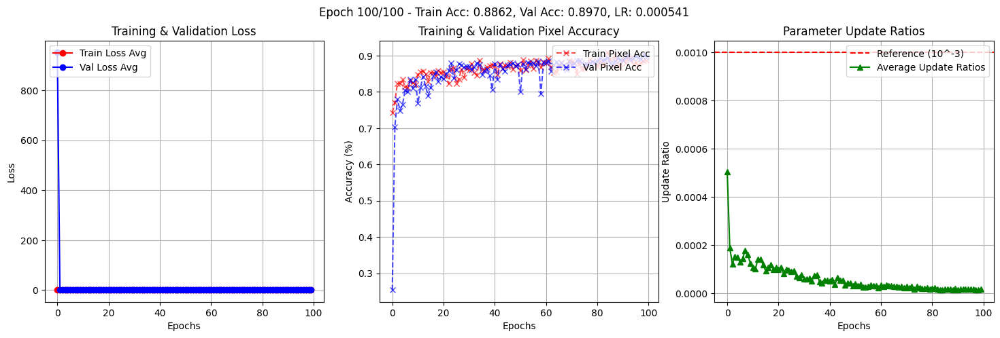

In [ ]:
# dict for metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Training for n_step
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validation for n_step
    vl_loss, vl_acc = validator(model, valid_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience
        torch.save(model.state_dict(), best_model_path)
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0: # or vl_acc > 0.92:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break

    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(
        data_dict,
        title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}"
    )

### Let's Test Our Model Now

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          0.2859
Accuracy             |          90.17%
Precision            |          0.8871
Recall               |          0.6755
F1 Score             |          0.7670

Confusion Matrix:
------------------------------------------------------------
        0        1     
------------------------------------------------------------
0    4849494   134883  
1     509236  1059987  
------------------------------------------------------------


### visuale test

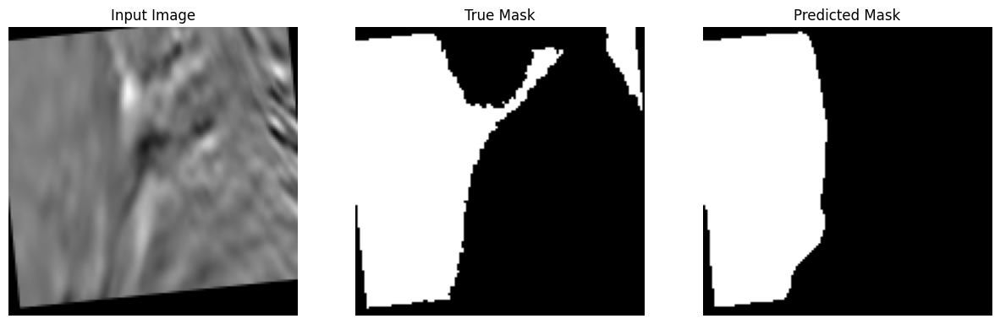

-------------------


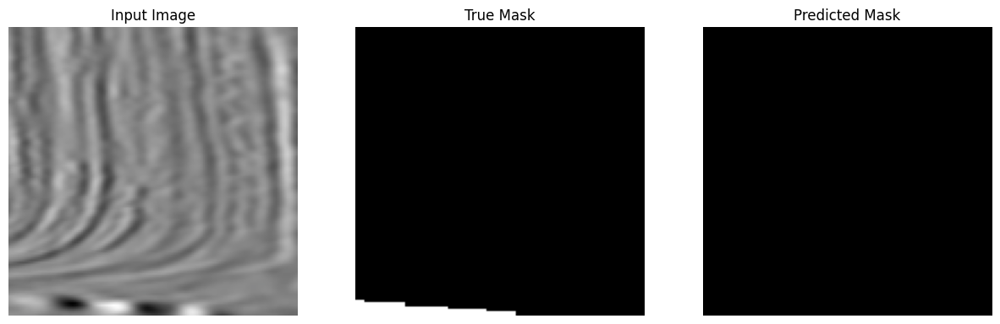

-------------------


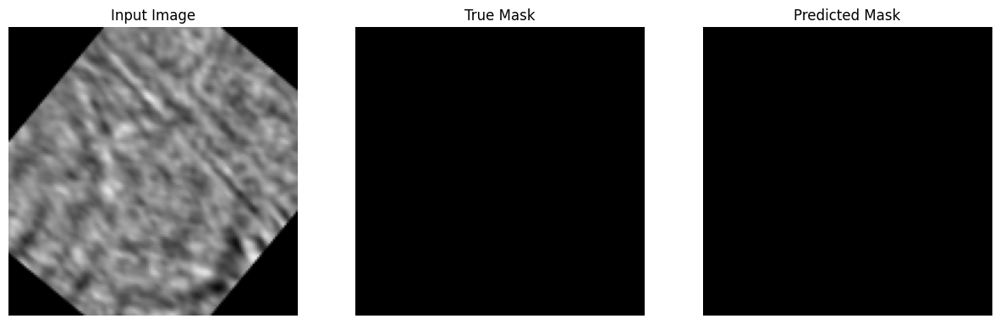

-------------------


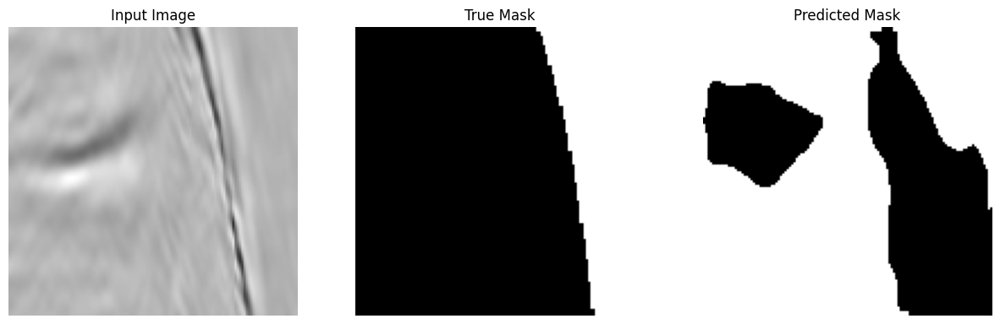

-------------------


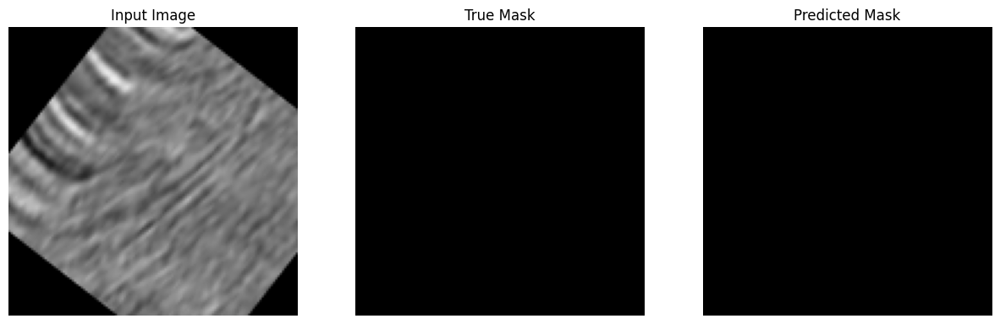

-------------------


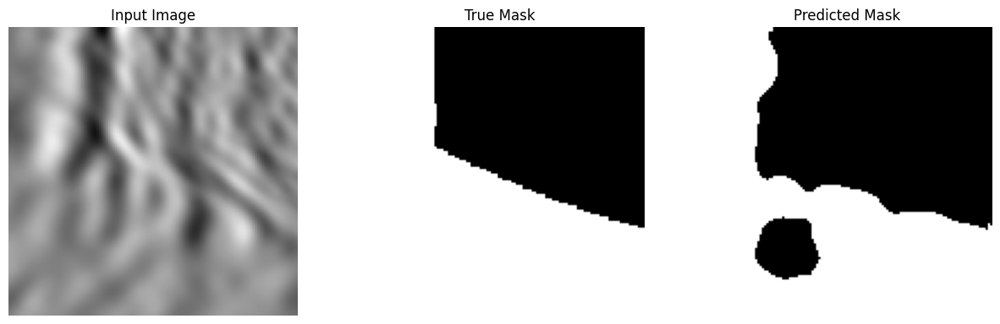

-------------------


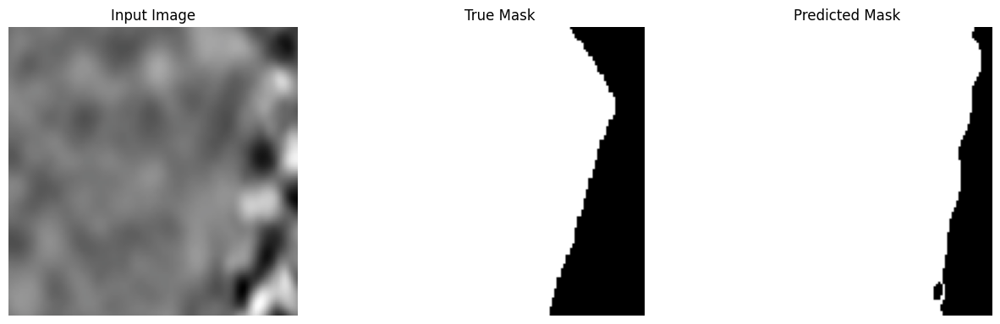

-------------------


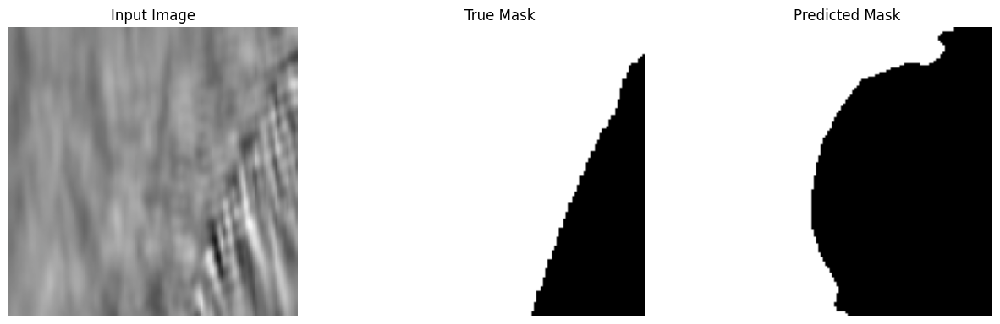

-------------------


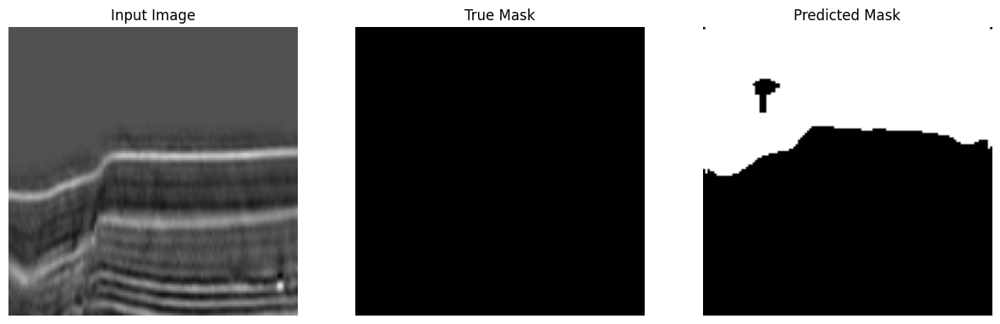

-------------------


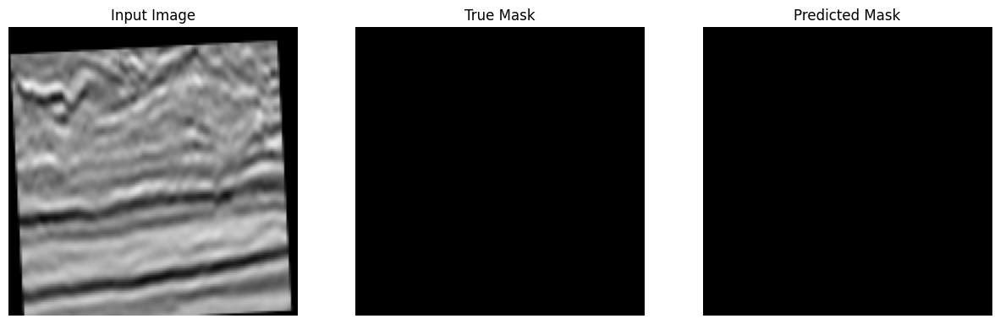

-------------------


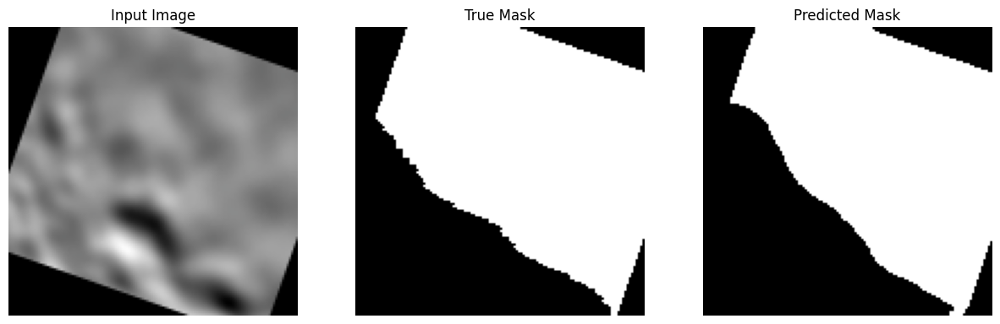

-------------------


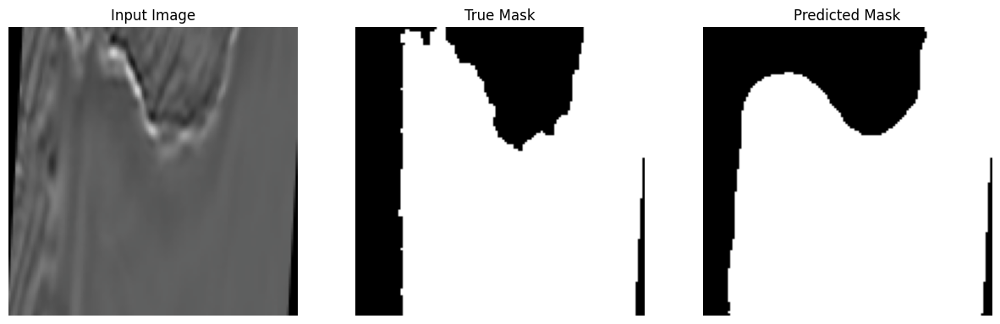

-------------------


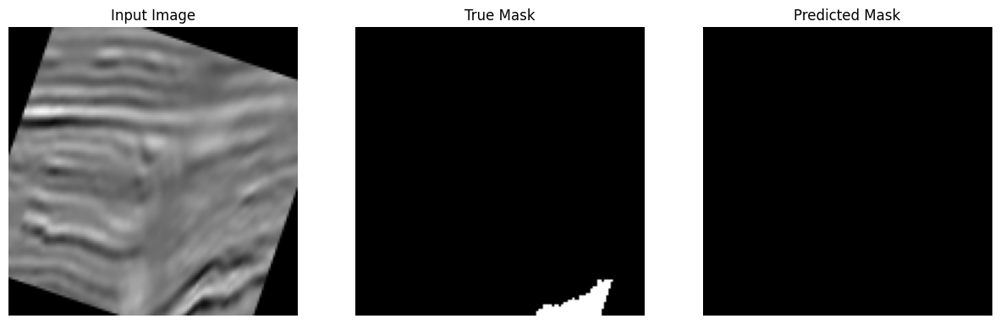

-------------------


In [ ]:
# we will display just a few examples
for idx, (img, mask) in enumerate(test_loader):
    img = img.to(device)
    mask = mask.to(device)

    with torch.no_grad():
        pred = torch.sigmoid(model(img))
        pred_mask = (pred > 0.5).float()

    # show images
    display_image_true_pred_mask(img[0], mask[0], pred_mask[0])

    # Wait for 2 seconds
    time.sleep(2)
    print("-------------------")
    # clear_output(wait=True)

    if idx == 100:
        break

# U-Net with [is_resnet=False, is_max_pool=True, is_double=True]:  

1. **No Residual Connections**  
2. **Double Convolutional Layers**  
3. **Standard Max Pooling**

### Init all Our Objects (Model, Criterion, Optimizer, ...)

In [ ]:
# Initialize UNet model
model = UNet(
    in_ch=in_ch,
    is_resnet=False,
    is_max_pool=True,
    is_double=True
)
model.to(device)
params, memory = model.get_model_size()
print(f"Trainable parameters: {params} (~{memory:.2f} MB)")

# Loss Function for segmentation
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

Trainable parameters: 18465048 (~70.44 MB)


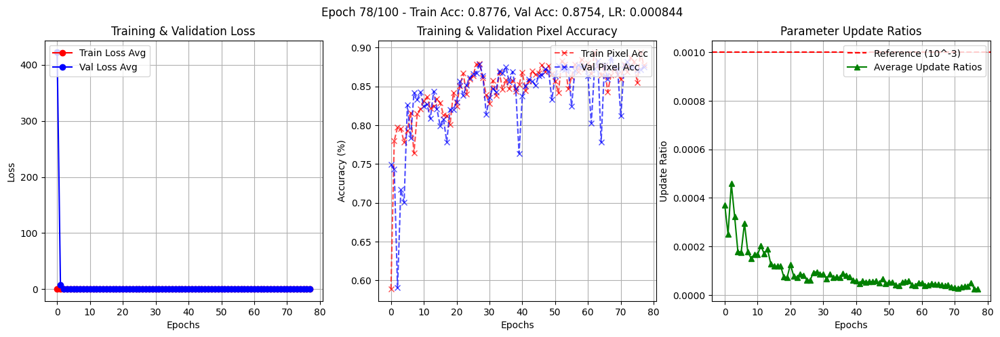

No improvement in validation accuracy. 0 epochs left until early stopping.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# dict for metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Training for n_step
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validation for n_step
    vl_loss, vl_acc = validator(model, valid_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience
        torch.save(model.state_dict(), best_model_path)
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0: # or vl_acc > 0.92:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break

    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(
        data_dict,
        title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}"
    )

### Let's Test Our Model Now

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          0.2990
Accuracy             |          89.00%
Precision            |          0.8691
Recall               |          0.6368
F1 Score             |          0.7351

Confusion Matrix:
------------------------------------------------------------
        0        1     
------------------------------------------------------------
0    4832383   150589  
1     570434  1000194  
------------------------------------------------------------


### visuale test

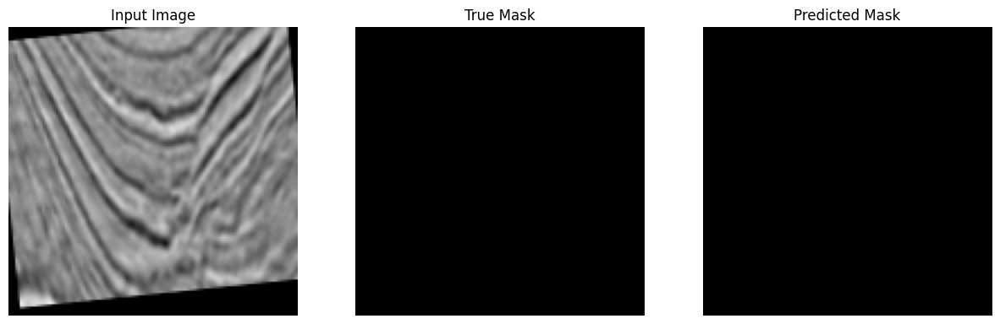

-------------------


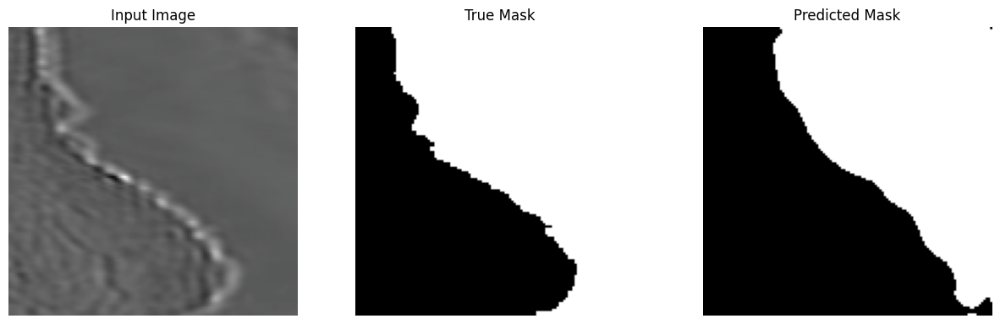

-------------------


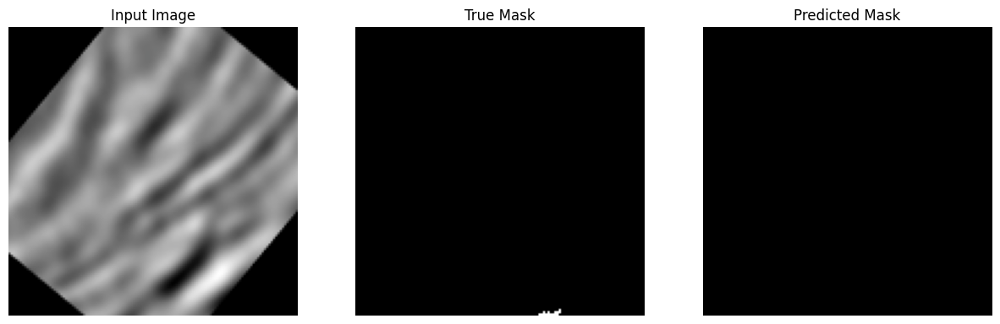

-------------------


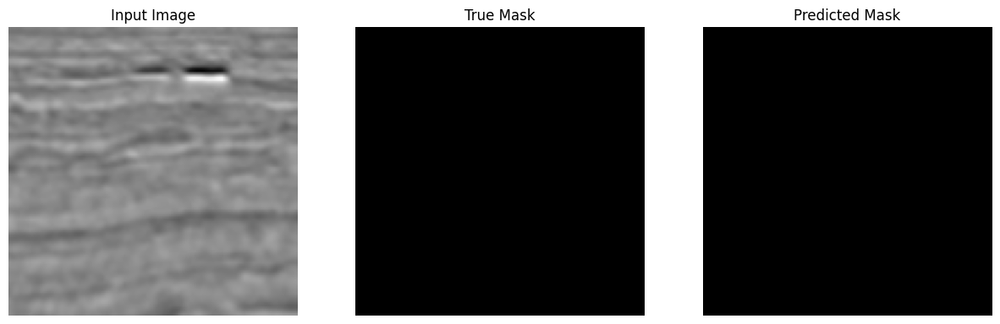

-------------------


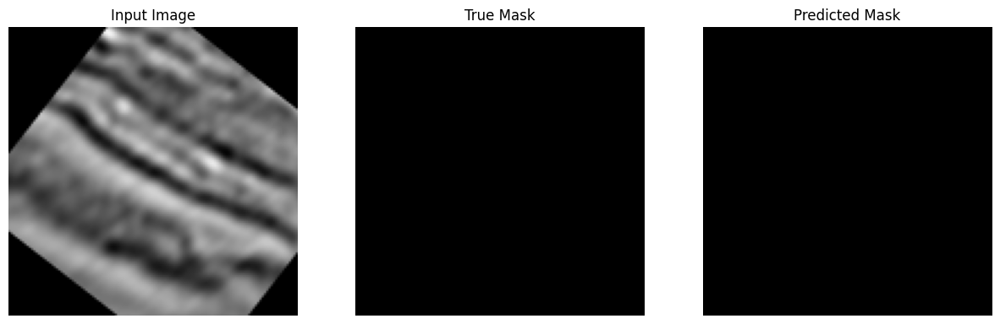

-------------------


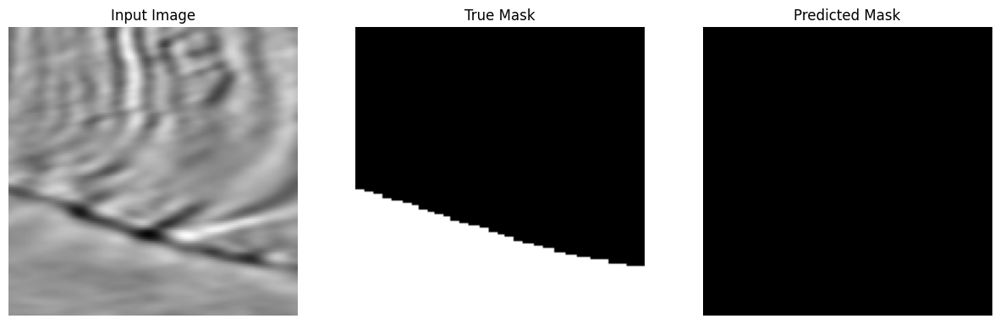

-------------------


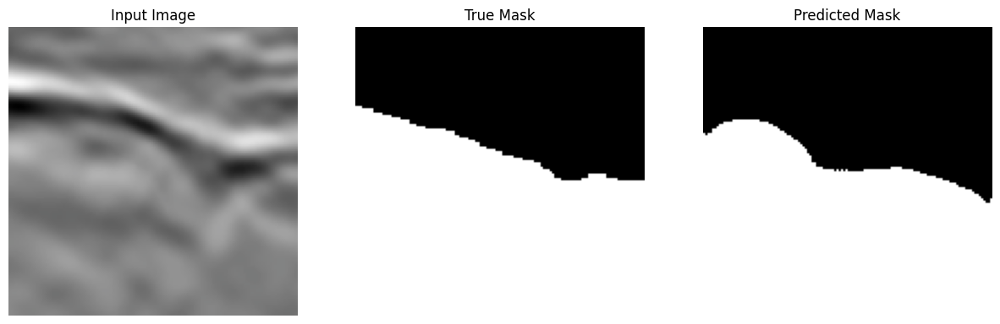

-------------------


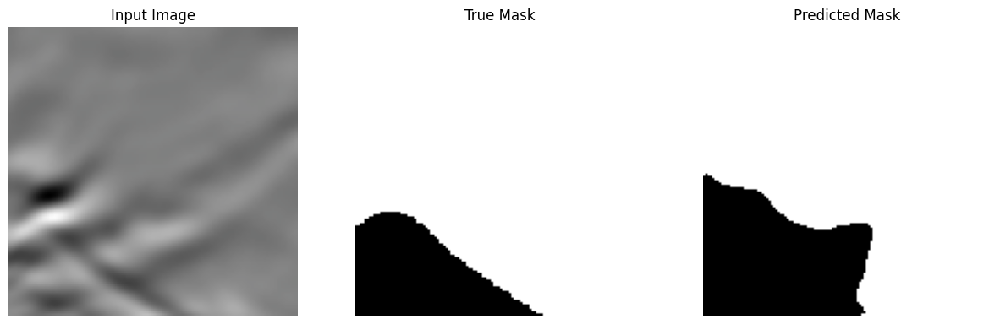

-------------------


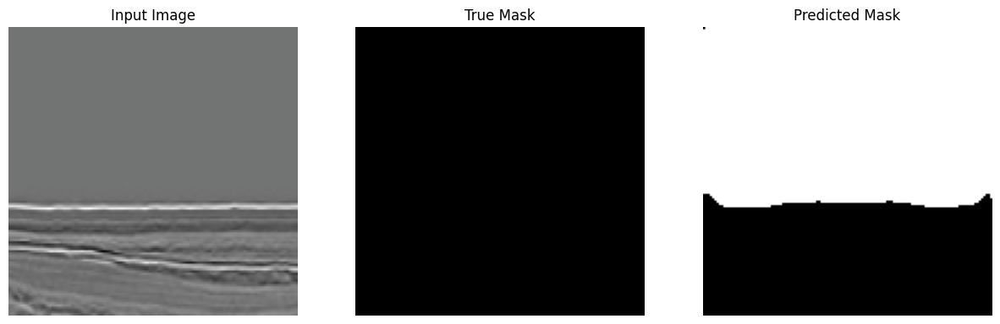

-------------------


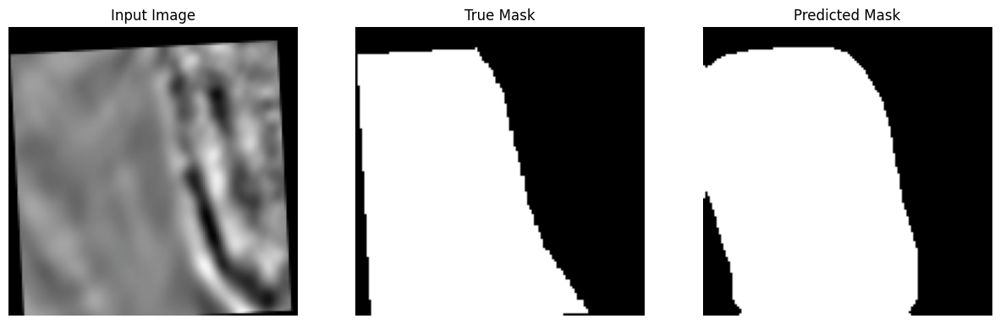

-------------------


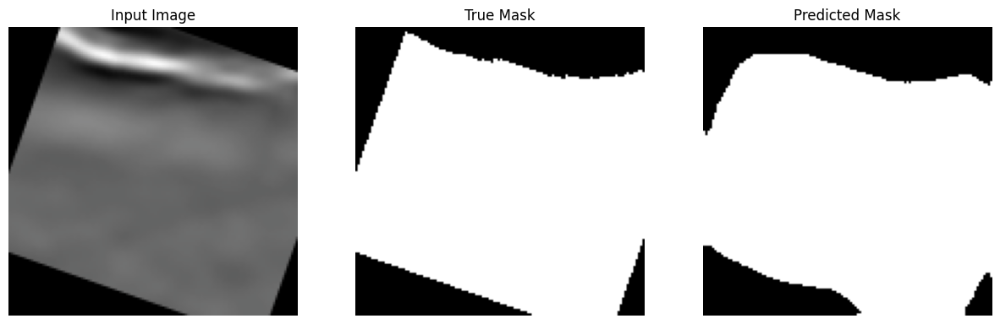

-------------------


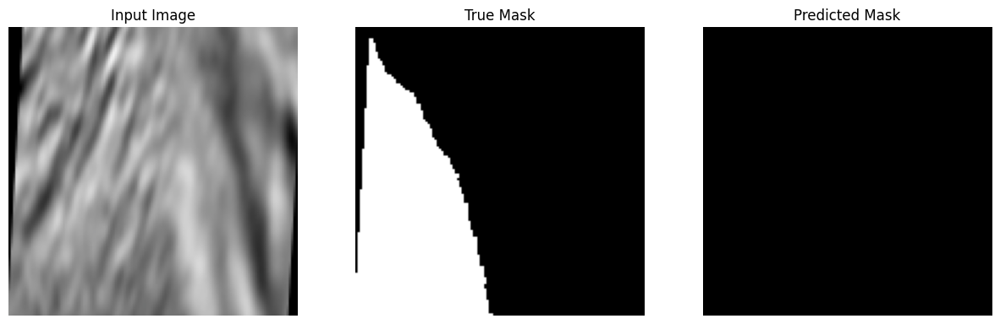

-------------------


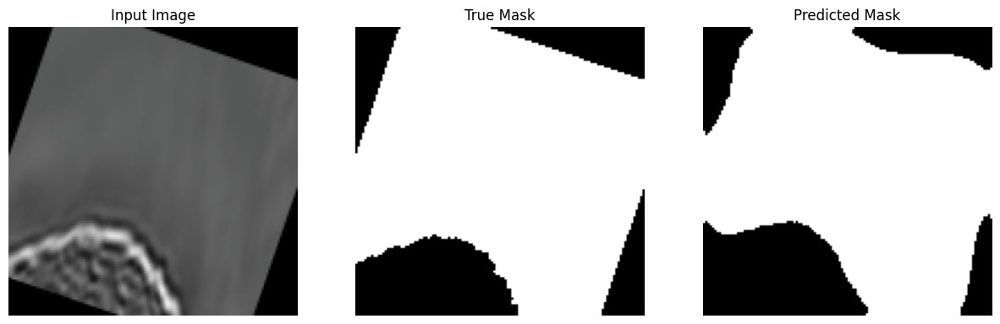

-------------------


In [ ]:
# we will display just a few examples
for idx, (img, mask) in enumerate(test_loader):
    img = img.to(device)
    mask = mask.to(device)

    with torch.no_grad():
        pred = torch.sigmoid(model(img))
        pred_mask = (pred > 0.5).float()

    # show images
    display_image_true_pred_mask(img[0], mask[0], pred_mask[0])

    # Wait for 2 seconds
    time.sleep(2)
    print("-------------------")
    # clear_output(wait=True)

    if idx == 100:
        break

### Skip Connections

Skip connections are essential in U-Net architectures, and my experiments highlight their impact on segmentation performance.

**Key Benefits of Skip Connections:**  
- **Preserving Fine Details:**  
  Skip connections bridge the encoder and decoder, enabling high-resolution features from early layers to be directly combined with up-sampled features. This is crucial for recovering spatial details lost during down-sampling.  

- **Better Gradient Flow:**  
  By creating direct pathways, skip connections help mitigate vanishing gradient issues, making it easier to train deeper networks.  

**Experimental Observations:**  
- **With Skip Connections:**  
  The network achieved higher accuracy (~90.17%) and a better F1 score (~0.7670).  
- **Without Skip Connections:**  
  Performance dropped slightly (accuracy ~89.00%, F1 score ~0.7351), indicating that even a modest removal of skip connections leads to a loss of detail and weaker segmentation performance.  

**Alternatives to Concatenation:**  
I focused on the standard approach of concatenating feature maps, as it preserves all information from both the encoder and decoder. However, other strategies exist:  
- **Element-wise Addition:** Might blend features too aggressively, potentially losing distinctive details.  
- **Max/Min Operations:** Could oversimplify the fusion process, limiting the ability to capture complementary information effectively.  

**Conclusion:**  
Skip connections are critical for maintaining spatial details and boosting overall performance. My experiments confirm that including them—especially through concatenation—provides a clear advantage over architectures without them.

# U-Net with [is_resnet=True, is_max_pool=False, is_double=True]:  

1. **Residual Connections**  
2. **Double Convolutional Layers**  
3. **Conv layer with stride = 2 ( same effect as max pooling)**

### Init all Our Objects (Model, Criterion, Optimizer, ...)

In [ ]:
# Initialize UNet model
model = UNet(
    in_ch=in_ch,
    is_resnet=True,
    is_max_pool=False,
    is_double=True
)
model.to(device)

params, memory = model.get_model_size()
print(f"Trainable parameters: {params} (~{memory:.2f} MB)")

# Loss Function for segmentation
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

Trainable parameters: 52936728 (~201.94 MB)


In [ ]:
# dict for metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Training for n_step
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validation for n_step
    vl_loss, vl_acc = validator(model, valid_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience
        torch.save(model.state_dict(), best_model_path)
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0: # or vl_acc > 0.92:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break

    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(
        data_dict,
        title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}"
    )

No improvement in validation accuracy. -1 epochs left until early stopping.
Stopping early due to lack of improvement in validation accuracy.


### Let's Test Our Model Now

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |        842.8423
Accuracy             |          75.99%
Precision            |          0.8750
Recall               |          0.0000
F1 Score             |          0.0000

Confusion Matrix:
------------------------------------------------------------
        0        1     
------------------------------------------------------------
0    4980137     1     
1    1573455     7     
------------------------------------------------------------


### visuale test

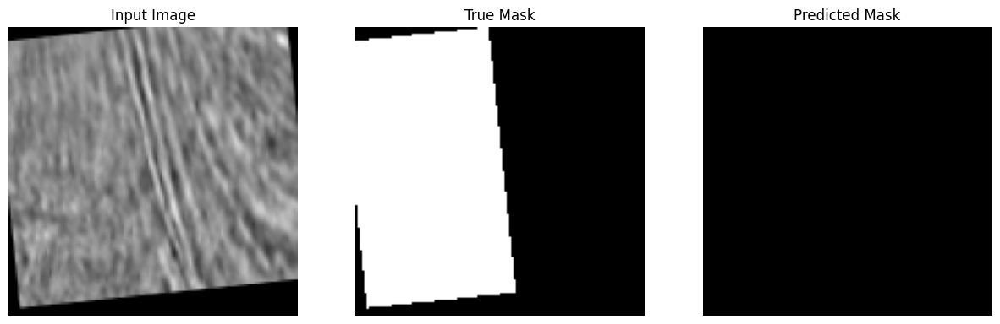

-------------------


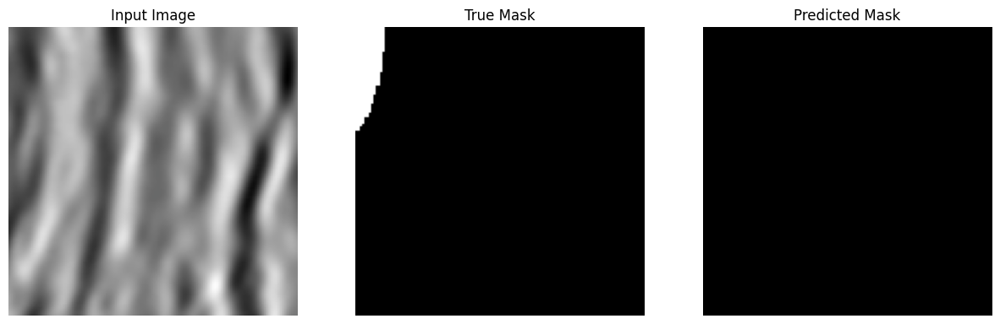

-------------------


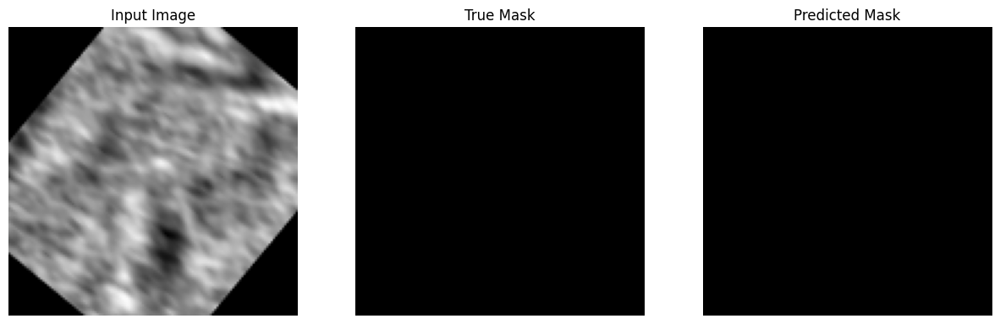

-------------------


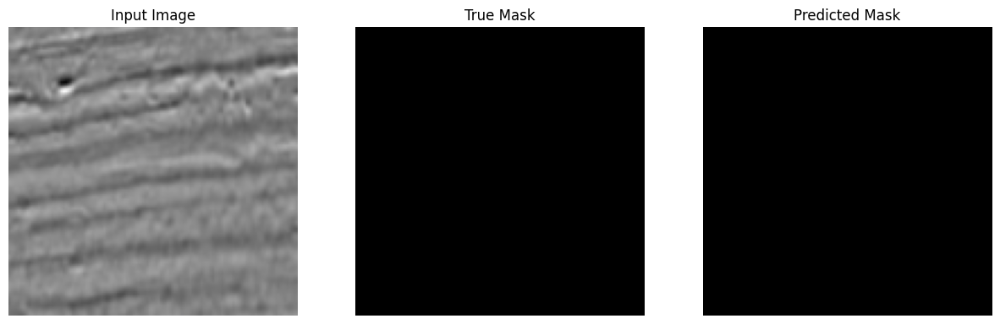

-------------------


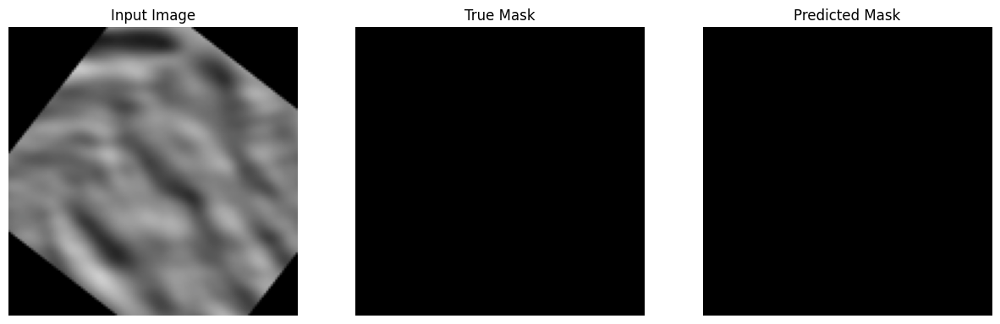

-------------------


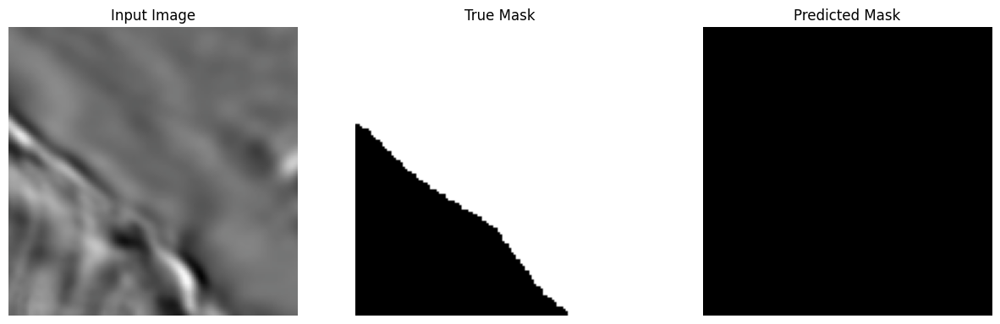

-------------------


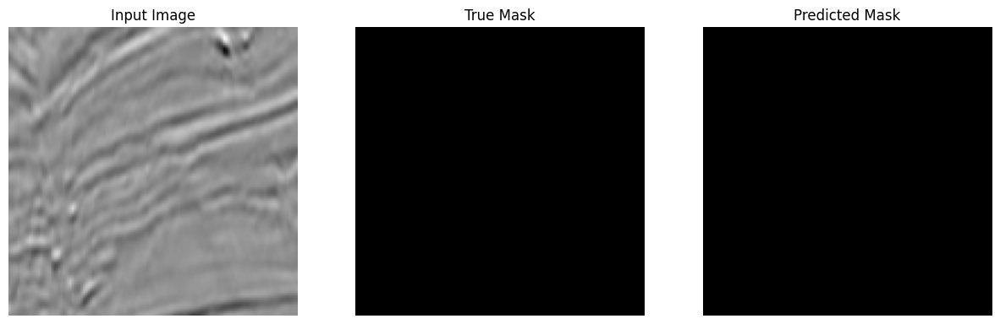

-------------------


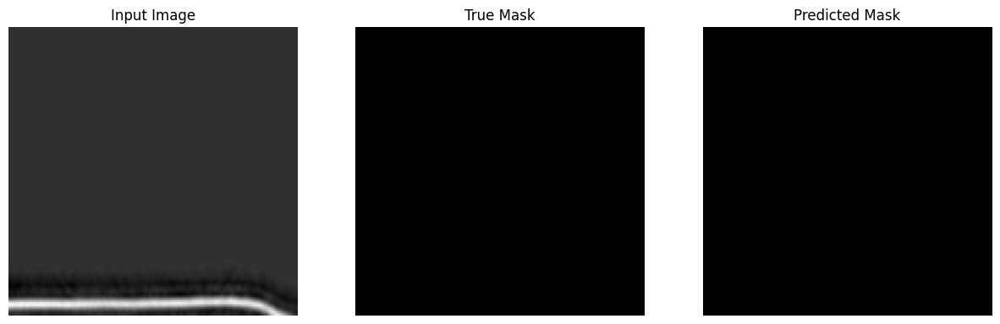

-------------------


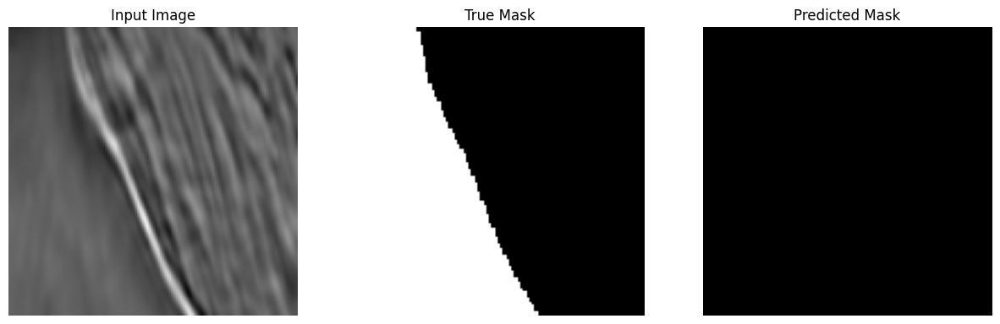

-------------------


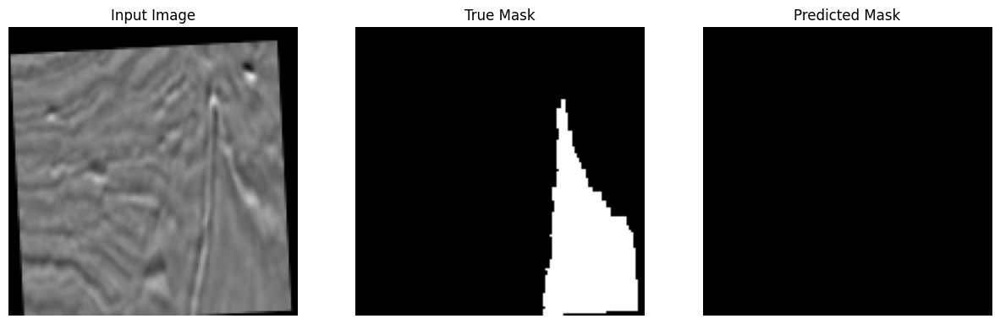

-------------------


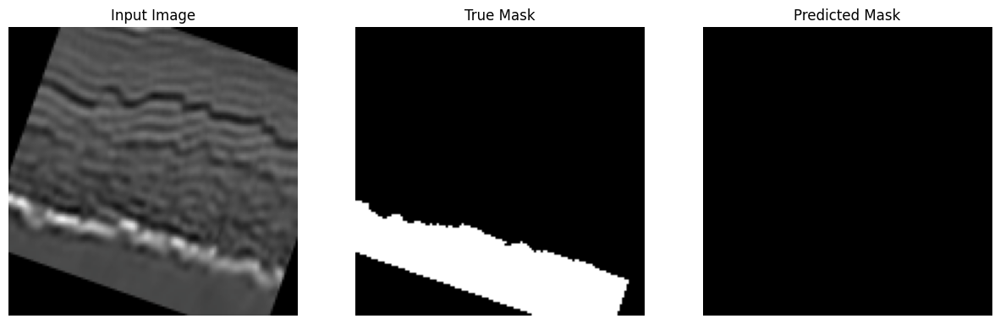

-------------------


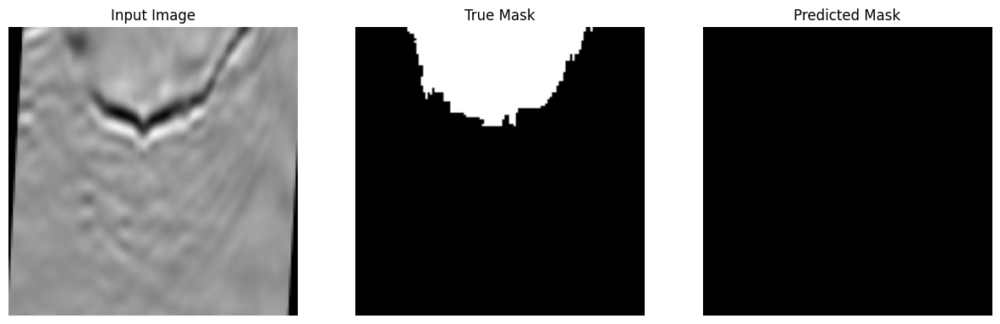

-------------------


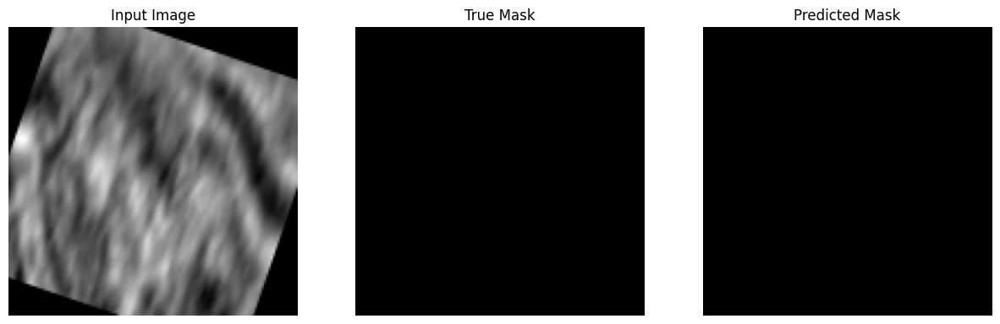

-------------------


In [ ]:
# we will display just a few examples
for idx, (img, mask) in enumerate(test_loader):
    img = img.to(device)
    mask = mask.to(device)

    with torch.no_grad():
        pred = torch.sigmoid(model(img))
        pred_mask = (pred > 0.5).float()

    # show images
    display_image_true_pred_mask(img[0], mask[0], pred_mask[0])

    # Wait for 2 seconds
    time.sleep(2)
    print("-------------------")
    # clear_output(wait=True)

    if idx == 100:
        break

### Max Pooling

Our experiments compared two down-sampling strategies within the U-Net architecture:

- **Max Pooling:**  
  With standard max pooling, the network achieved an accuracy of about 90.17% and an F1 score of 0.7670. This approach preserves the strongest activations within each window, which helps retain the most salient features for segmentation.

- **Strided Convolution:**  
  When max pooling was replaced by a convolution with a stride of 2, the performance degraded substantially (accuracy dropped to around 75.99%, and the recall essentially dropped to 0, yielding an F1 score of 0). This suggests that the learnable down-sampling in the strided convolution did not effectively capture the necessary features, possibly because it failed to robustly highlight the dominant responses that are critical in segmentation tasks.

  Another issue with Pooling using a Conv Layer is that it increases the number of parameters.

**Conclusion:**  
While both methods reduce spatial dimensions, our experiments clearly show that standard max pooling is far superior in this context. It appears that the fixed, non-learnable nature of max pooling better preserves key features compared to strided convolutions.

# U-Net with [is_resnet=True, is_max_pool=True, is_double=False]:  

1. **Residual Connections**  
2. **One Single Convolutional Layer**  
3. **Standard Max Pooling**

### Init all Our Objects (Model, Criterion, Optimizer, ...)

In [ ]:
# Initialize UNet model
model = UNet(
    in_ch=in_ch,
    is_resnet=True,
    is_max_pool=True,
    is_double=False
)
model.to(device)

params, memory = model.get_model_size()
print(f"Trainable parameters: {params} (~{memory:.2f} MB)")

# Loss Function for segmentation
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

Trainable parameters: 15327681 (~58.47 MB)


In [ ]:
# dict for metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Training for n_step
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validation for n_step
    vl_loss, vl_acc = validator(model, valid_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience
        torch.save(model.state_dict(), best_model_path)
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0: # or vl_acc > 0.92:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break

    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(
        data_dict,
        title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}"
    )

No improvement in validation accuracy. -2 epochs left until early stopping.
Stopping early due to lack of improvement in validation accuracy.


### Let's Test Our Model Now

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          6.3371
Accuracy             |          31.39%
Precision            |          0.2390
Recall               |          0.8506
F1 Score             |          0.3731

Confusion Matrix:
------------------------------------------------------------
        0        1     
------------------------------------------------------------
0     719236  4261215  
1     234996  1338153  
------------------------------------------------------------


### visuale test

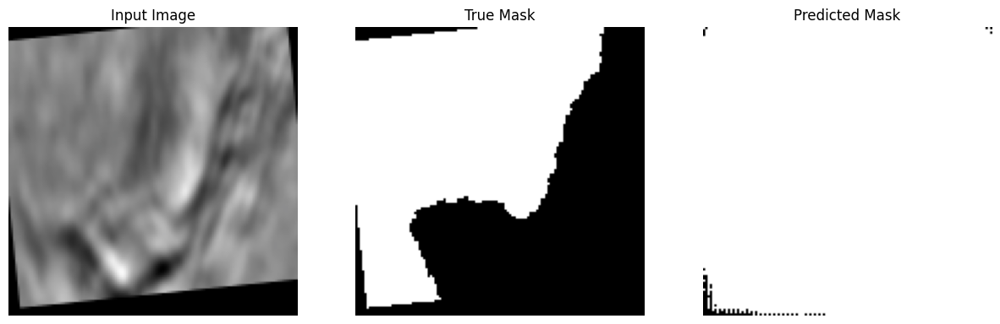

-------------------


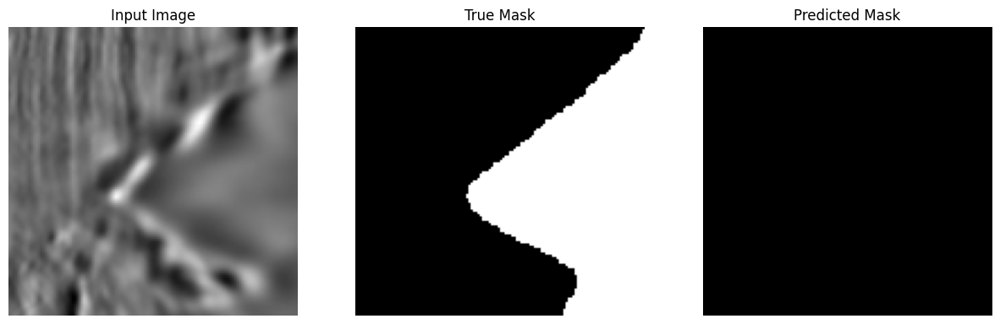

-------------------


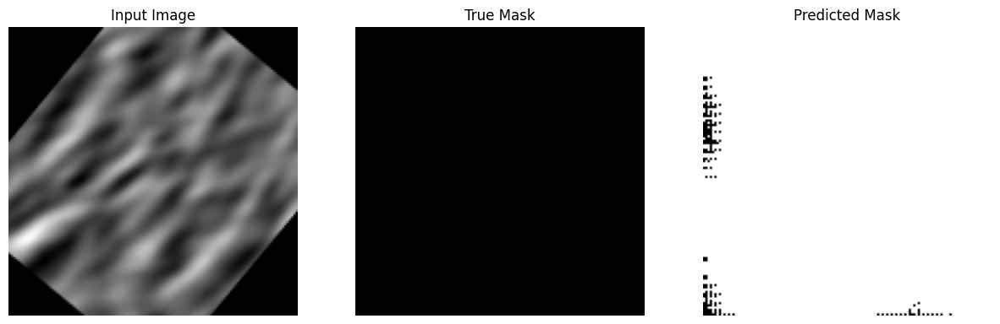

-------------------


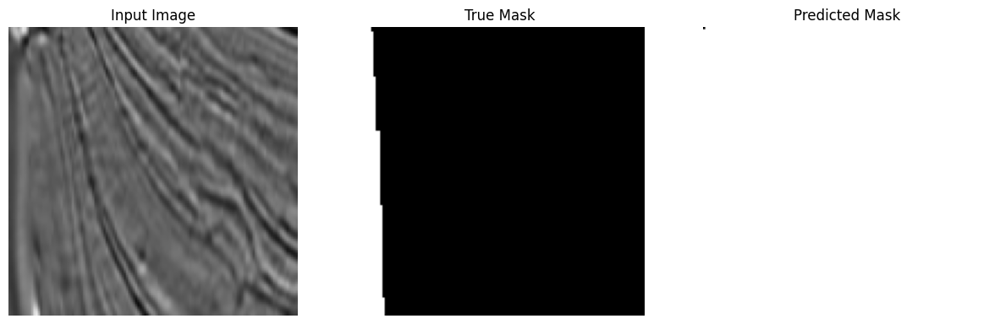

-------------------


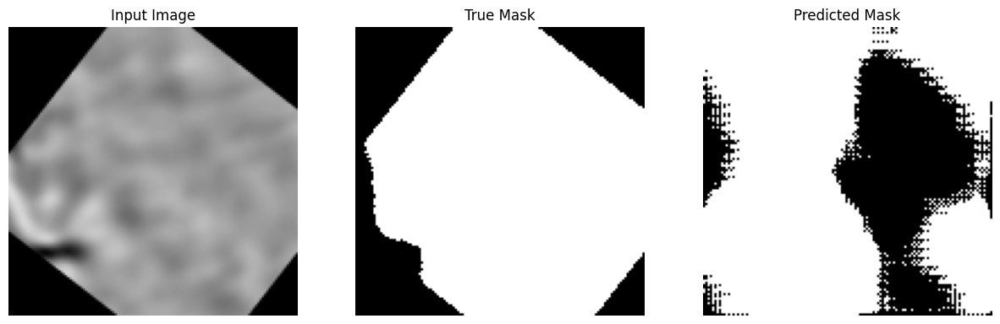

-------------------


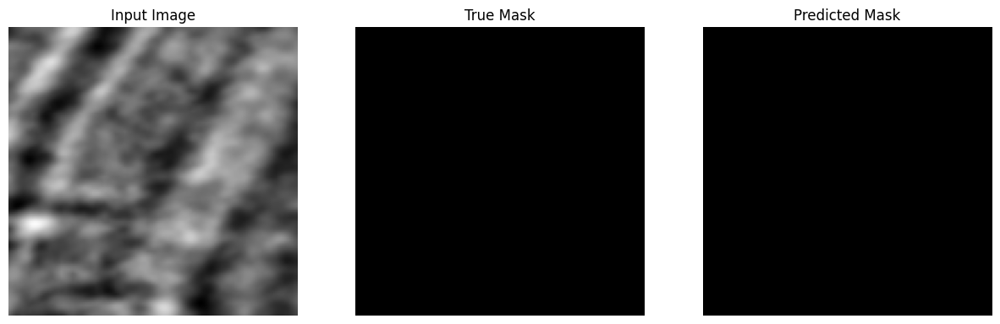

-------------------


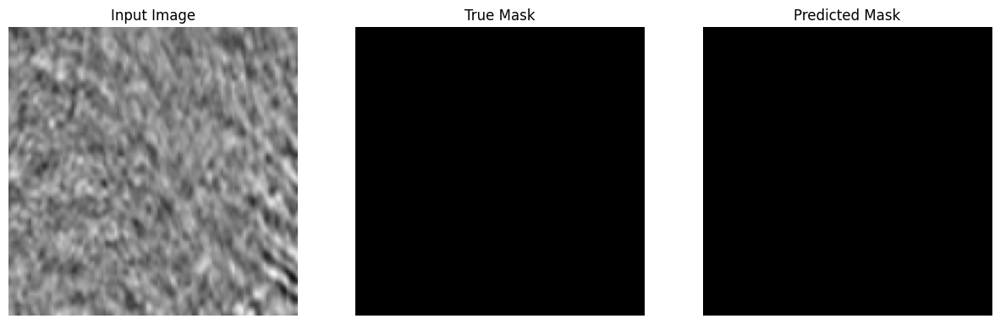

-------------------


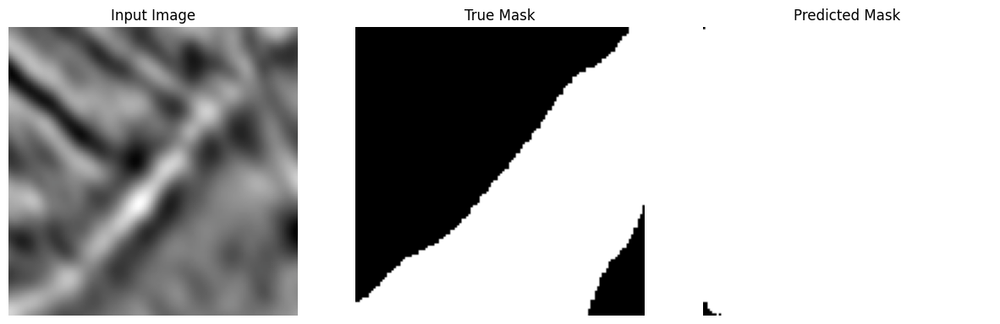

-------------------


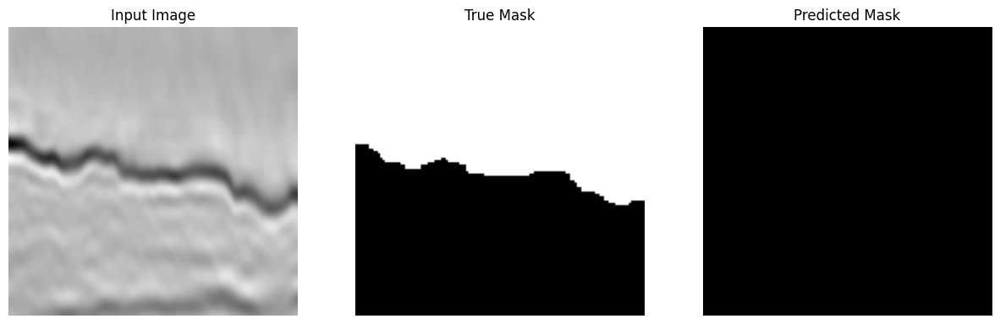

-------------------


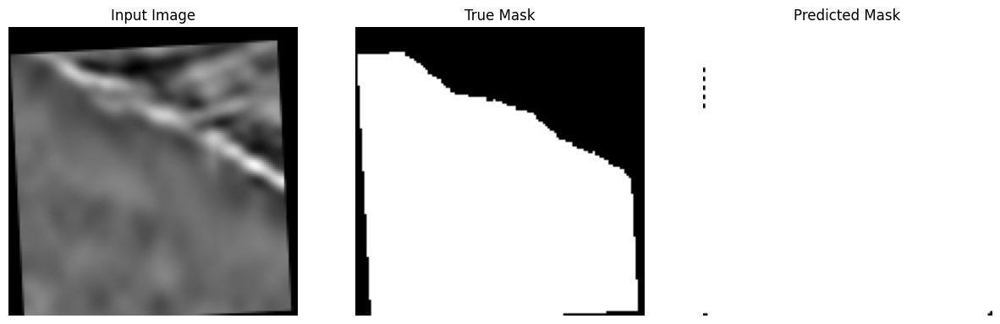

-------------------


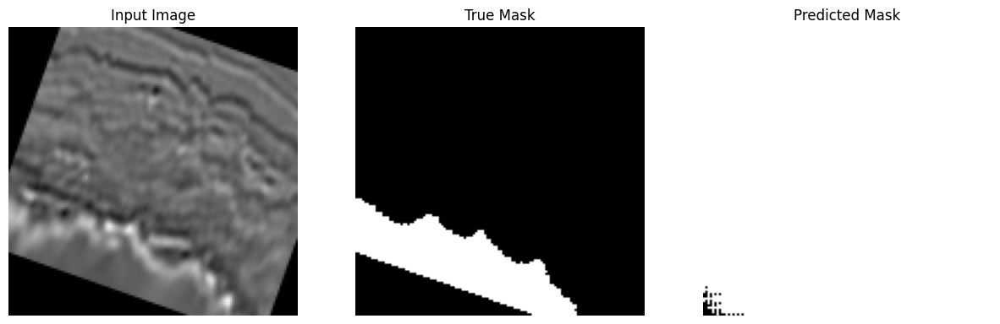

-------------------


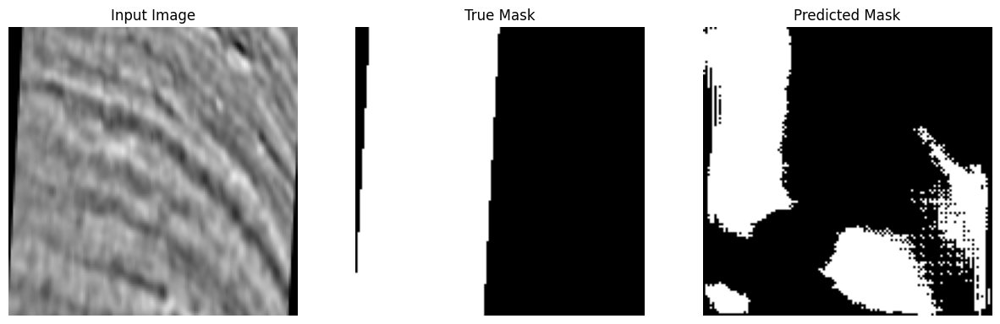

-------------------


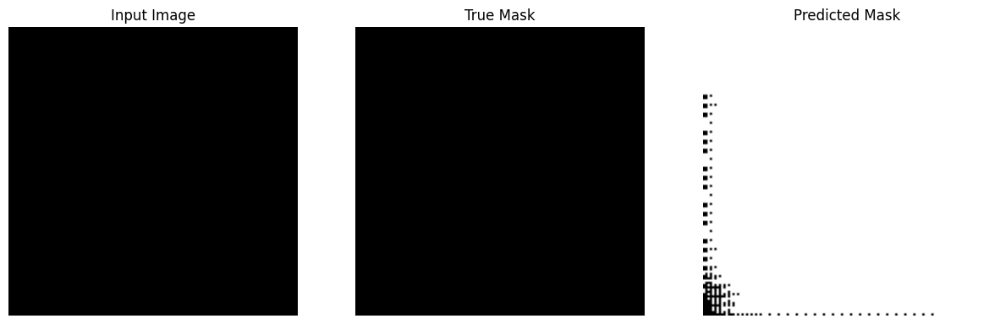

-------------------


In [ ]:
# we will display just a few examples
for idx, (img, mask) in enumerate(test_loader):
    img = img.to(device)
    mask = mask.to(device)

    with torch.no_grad():
        pred = torch.sigmoid(model(img))
        pred_mask = (pred > 0.5).float()

    # show images
    display_image_true_pred_mask(img[0], mask[0], pred_mask[0])

    # Wait for 2 seconds
    time.sleep(2)
    print("-------------------")
    # clear_output(wait=True)

    if idx == 100:
        break

# U-Net with [is_resnet=True, is_max_pool=True, is_double=True]:  

1. **Residual Connections**  
2. **One Single Convolutional Layer**  
3. **Standard Max Pooling**
4. **But with Threshold = 0.75**

### Init all Our Objects (Model, Criterion, Optimizer, ...)

In [ ]:
# threshold
threshold = 0.75

# Initialize UNet model
model = UNet(
    in_ch=in_ch,
    is_resnet=True,
    is_max_pool=True,
    is_double=True
)
model.to(device)

params, memory = model.get_model_size()
print(f"Trainable parameters: {params} (~{memory:.2f} MB)")

# Loss Function for segmentation
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

Trainable parameters: 31000728 (~118.26 MB)


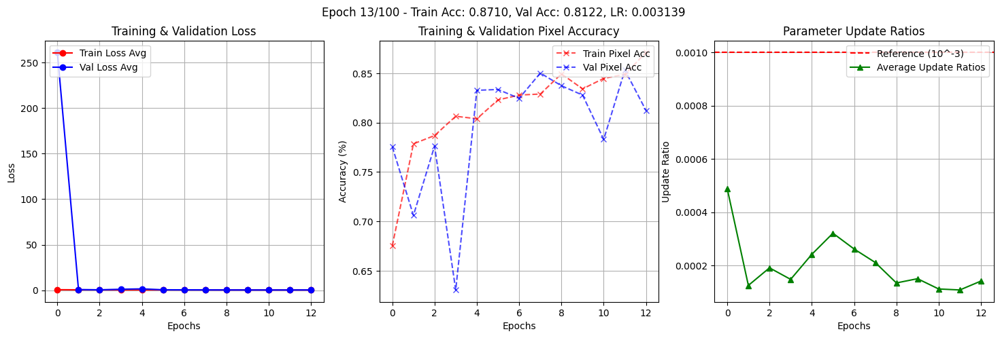

In [ ]:
# dict for metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Training for n_step
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validation for n_step
    vl_loss, vl_acc = validator(model, valid_loader, criterion, n_step, device, threshold)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience
        torch.save(model.state_dict(), best_model_path)
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0: # or vl_acc > 0.92:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break

    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(
        data_dict,
        title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}"
    )

### Let's Test Our Model with different thresholds

In [ ]:
for threshold in [round(x, 2) for x in range(40, 85, 5)]:
    print(f"========================[ threshold = {threshold} ]=====================================")
    tester(model, test_loader, criterion, 200, device, threshold)

### visuale test

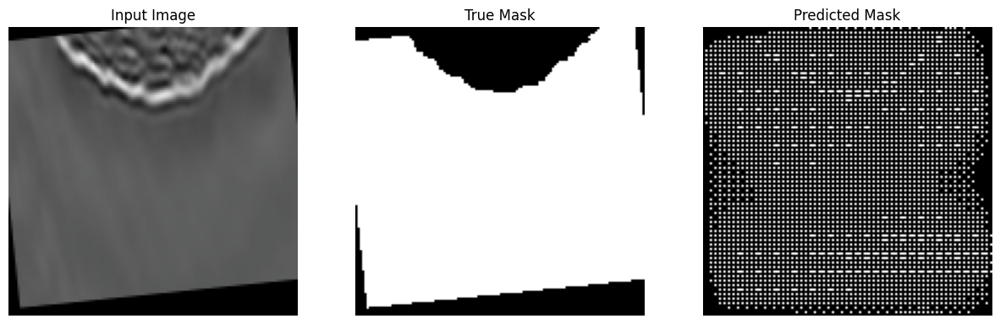

-------------------


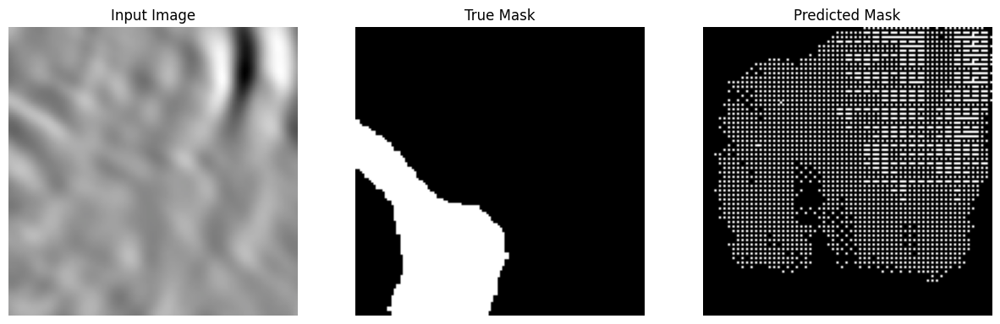

-------------------


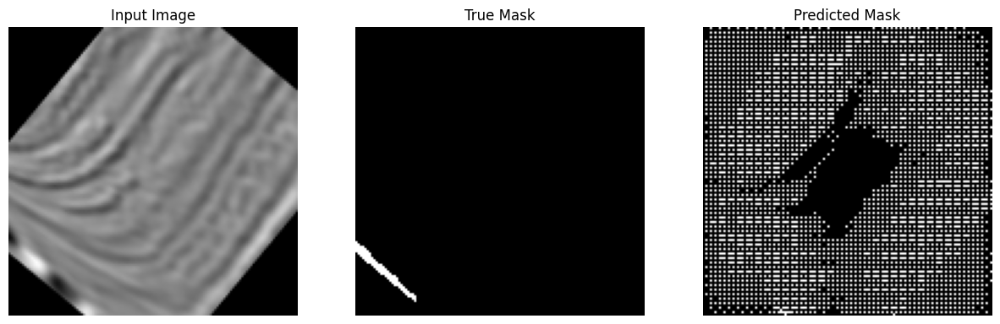

-------------------


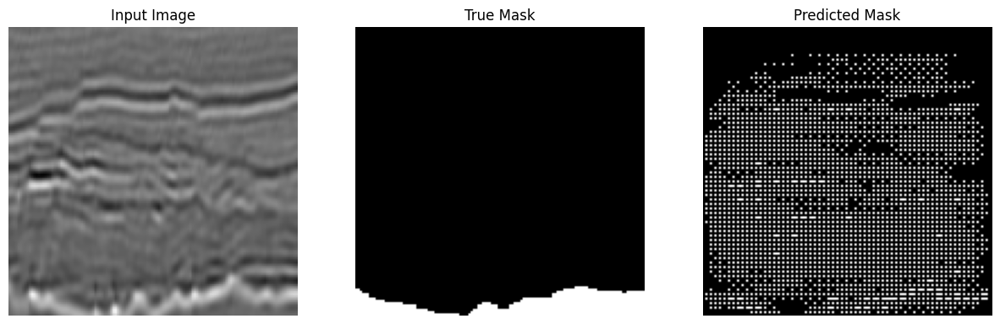

-------------------


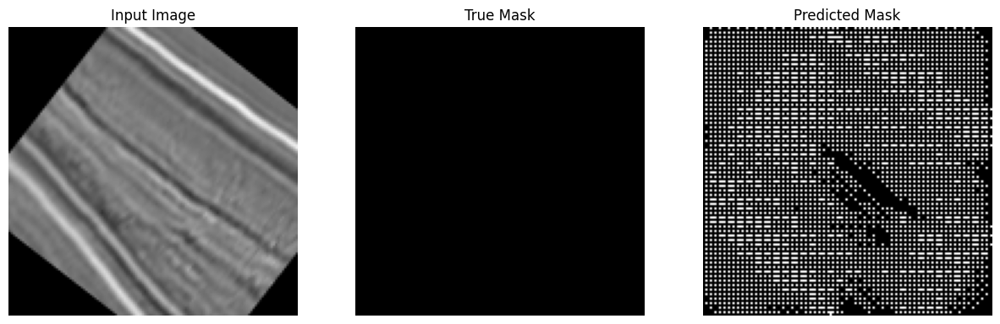

-------------------


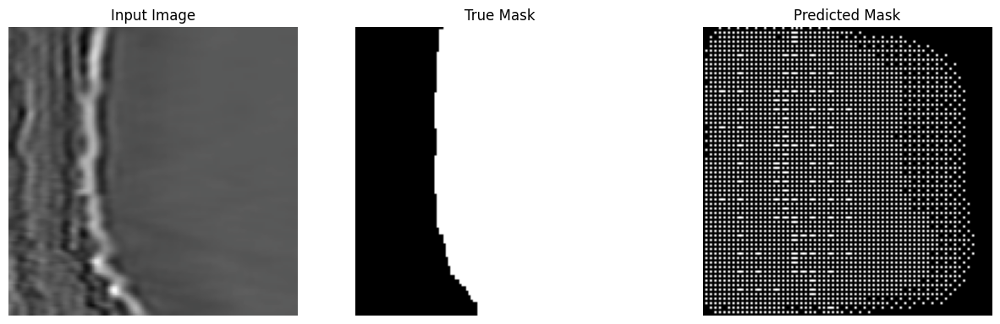

-------------------


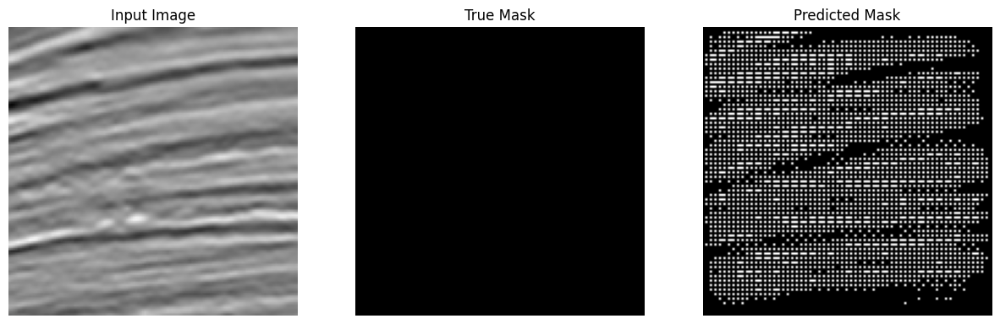

-------------------


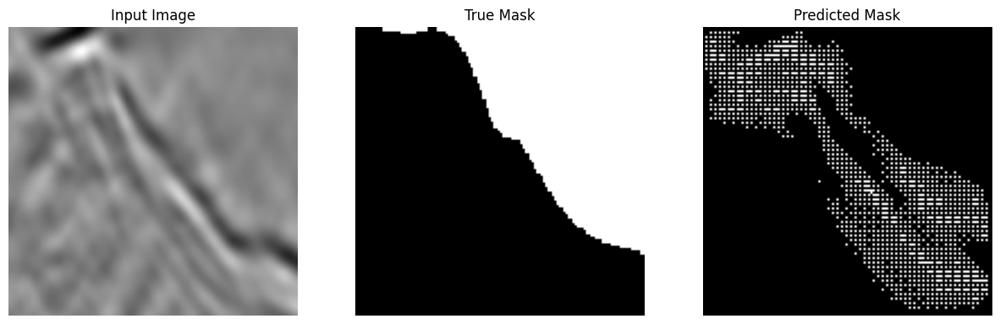

-------------------


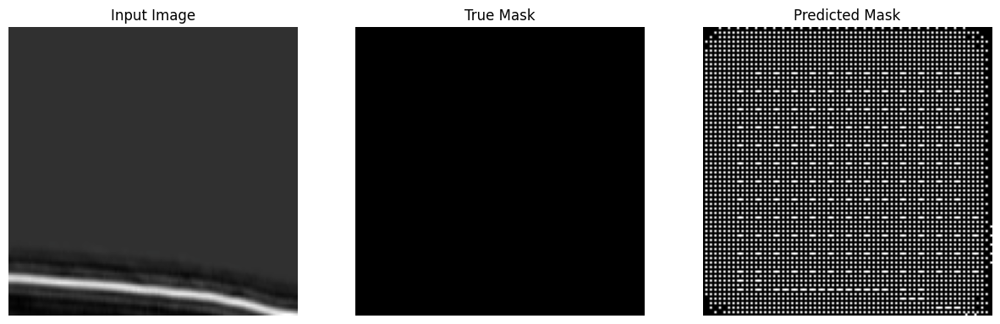

-------------------


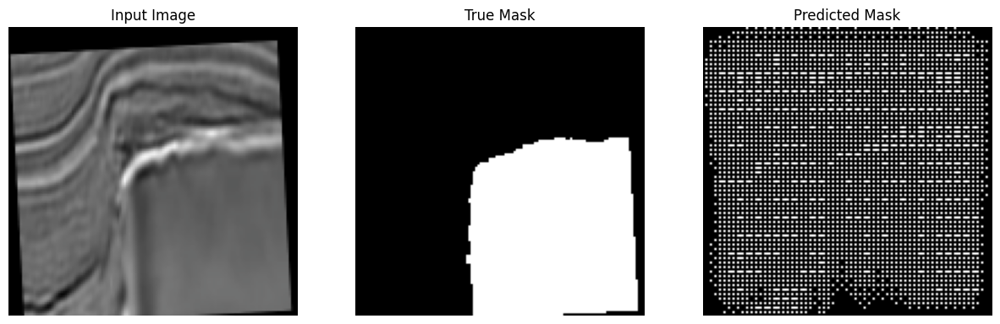

-------------------


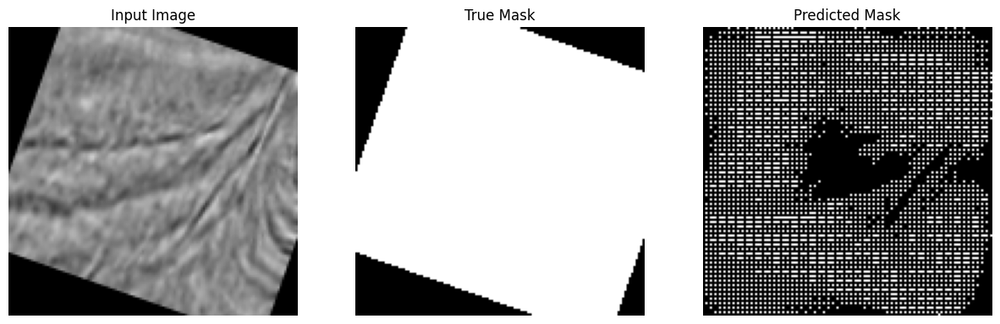

-------------------


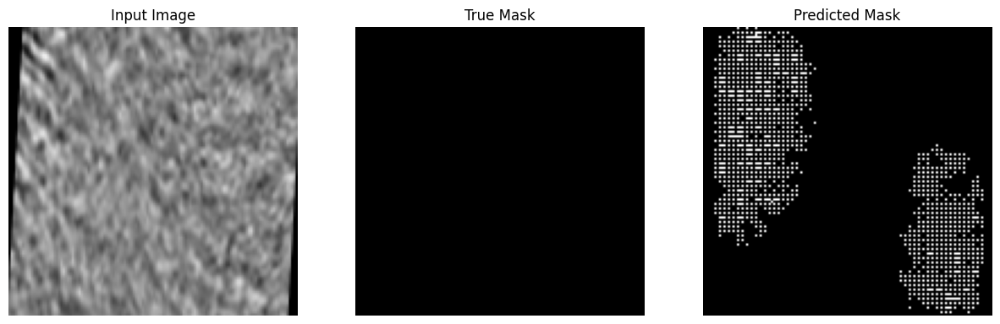

-------------------


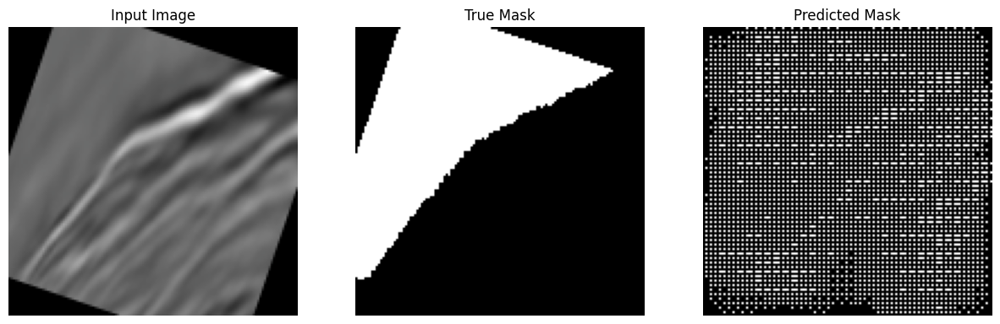

-------------------


In [ ]:
# we will display just a few examples
for idx, (img, mask) in enumerate(test_loader):
    img = img.to(device)
    mask = mask.to(device)

    with torch.no_grad():
        pred = torch.sigmoid(model(img))
        pred_mask = (pred > threshold).float()

    # show images
    display_image_true_pred_mask(img[0], mask[0], pred_mask[0])

    # Wait for 2 seconds
    time.sleep(2)
    print("-------------------")
    # clear_output(wait=True)

    if idx == 100:
        break

### Threshold for Inference

**Defining the Metrics:**  
- **Precision:**  
  Measures the ratio of true positive salt pixel predictions to all pixels predicted as salt. A high precision score means that when the model predicts salt, it is highly likely to be correct.  

- **Recall:**  
  Represents the ratio of true positive salt pixel predictions to all actual salt pixels. High recall ensures that most of the salt pixels in the image are detected.  

**Experimental Observations:**  
- **Threshold at 0.5 (Variant 1):**  
  The model achieved high precision (~0.8871) and reasonable recall (~0.6755), striking a good balance between the two metrics.  

- **Threshold at 0.75 (Variant 5):**  
  Increasing the threshold to 0.75 led to a significant drop in both precision (~0.2192) and recall (~0.2070). This suggests that a higher threshold makes the model overly conservative, missing many salt pixels (low recall) while still misclassifying non-salt pixels when it does make a prediction.  

**Strategies for Improvement:**  
- **Threshold Optimization:**  
  Rather than fixing the threshold at 0.5, analyzing the precision–recall curve can help determine an optimal threshold that best balances both metrics based on the task’s requirements.  

- **Modified Loss Functions:**  
  Using Dice loss or a combination of BCE and Dice loss can directly optimize the overlap between predicted and true masks, potentially improving both precision and recall.  

- **Post-Processing Techniques:**  
  Methods like conditional random fields (CRFs) or morphological operations can refine the segmentation masks further, improving the trade-off between precision and recall.  

**Conclusion:**  
The threshold choice plays a critical role in balancing precision and recall. My experiments show that while 0.5 provides a reasonable trade-off, increasing it too much (e.g., to 0.75) significantly degrades performance. A more systematic approach to threshold selection—along with tailored loss functions—can help better align the model with the specific needs of salt segmentation.

# U-Net with Fully Connected Neural Network

### Init all Our Objects (Model, Criterion, Optimizer, ...)

In [ ]:
# Initialize UNet model
model = FCN(
    in_ch=in_ch,
    im_size=im_size,
)
model.to(device)

# Loss Function for segmentation
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

In [ ]:
# dict for metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Training for n_step
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validation for n_step
    vl_loss, vl_acc = validator(model, valid_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience
        torch.save(model.state_dict(), best_model_path)
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0: # or vl_acc > 0.92:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break

    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(
        data_dict,
        title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}"
    )

No improvement in validation accuracy. -4 epochs left until early stopping.
Stopping early due to lack of improvement in validation accuracy.


### Let's Test Our Model Now

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          1.9026
Accuracy             |          60.18%
Precision            |          0.2328
Recall               |          0.2855
F1 Score             |          0.2565

Confusion Matrix:
------------------------------------------------------------
        0        1     
------------------------------------------------------------
0    3494076  1483431  
1    1126063   450030  
------------------------------------------------------------


### visuale test

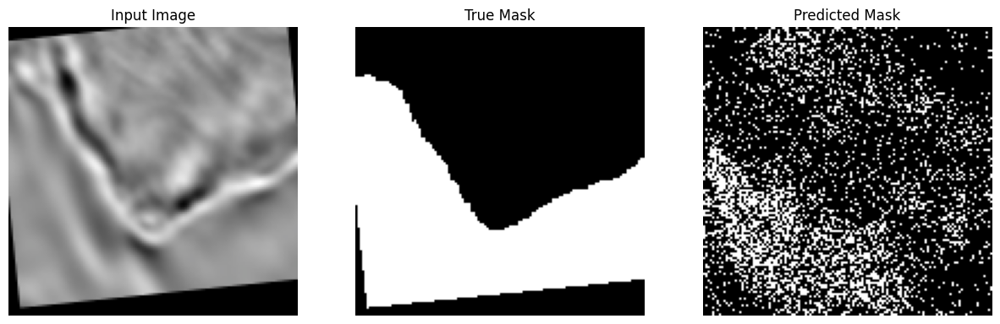

-------------------


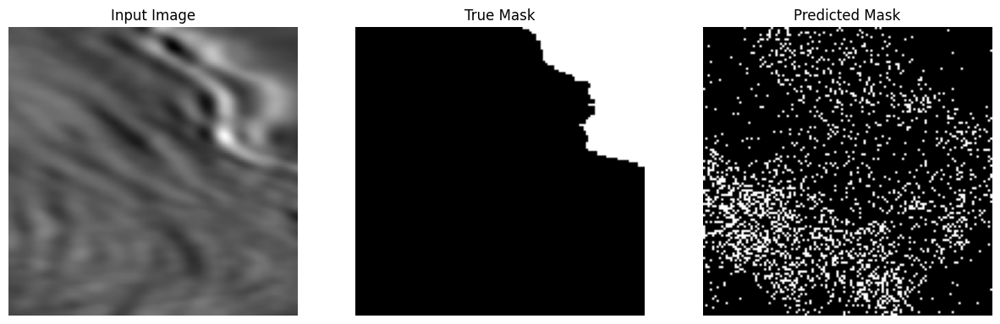

-------------------


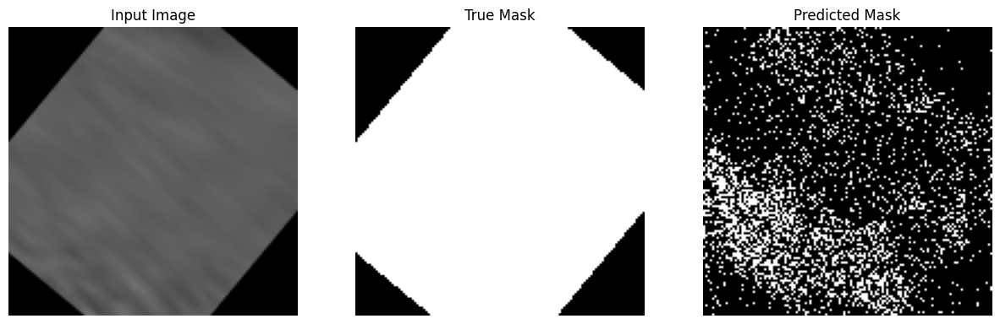

-------------------


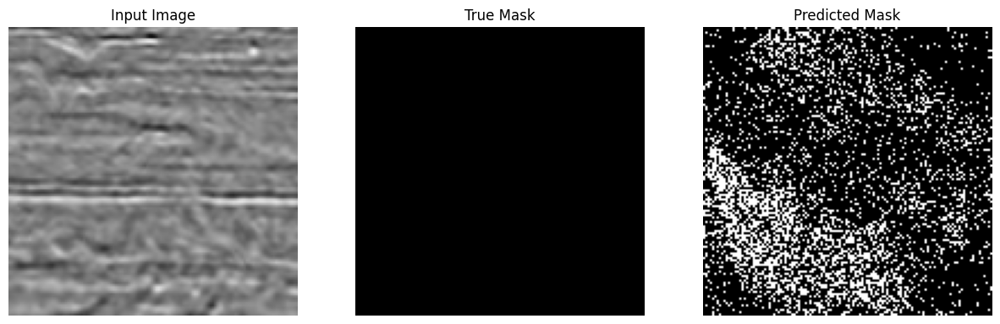

-------------------


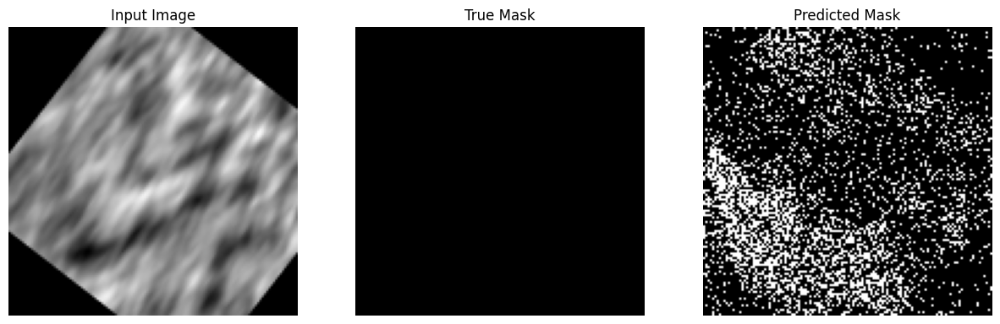

-------------------


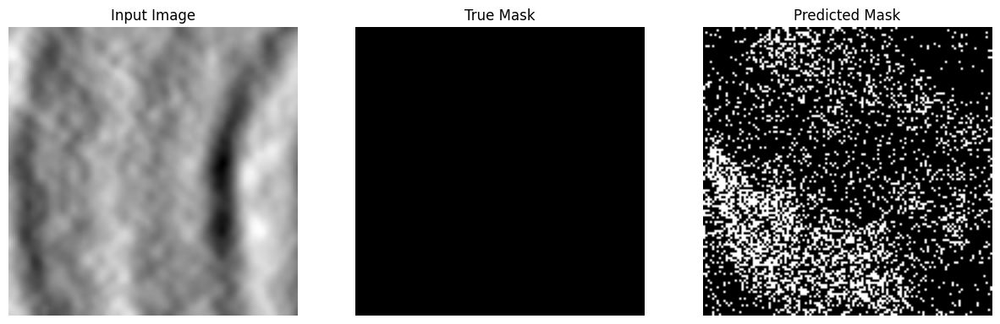

-------------------


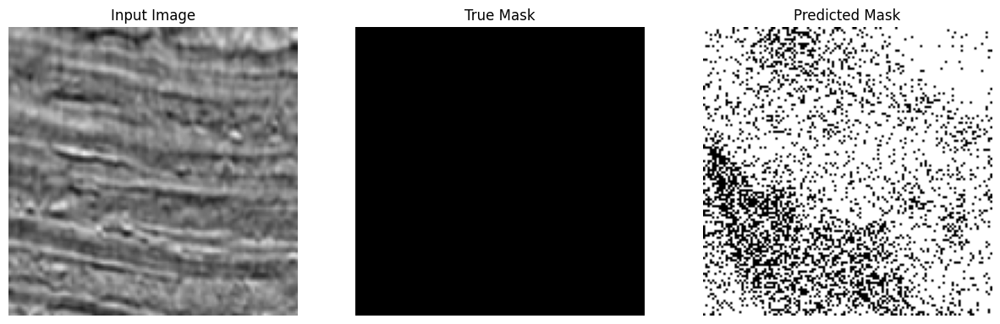

-------------------


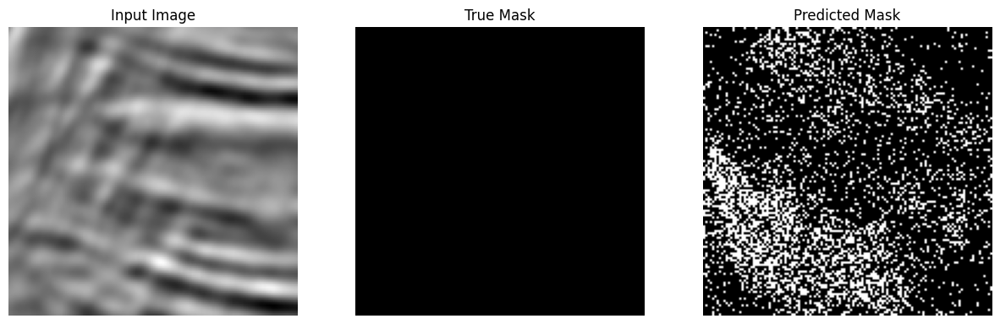

-------------------


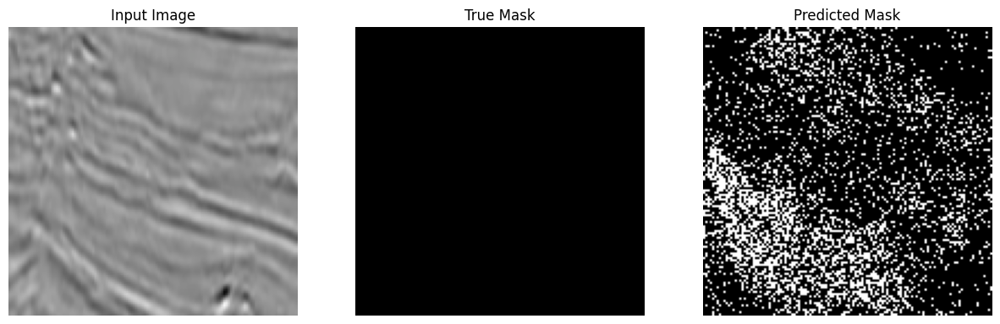

-------------------


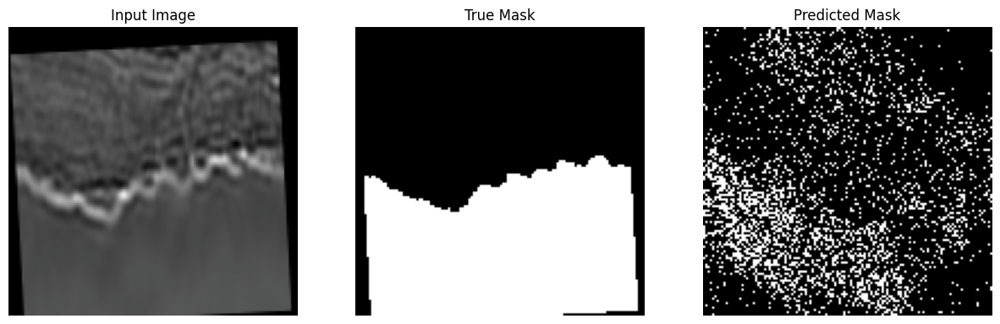

-------------------


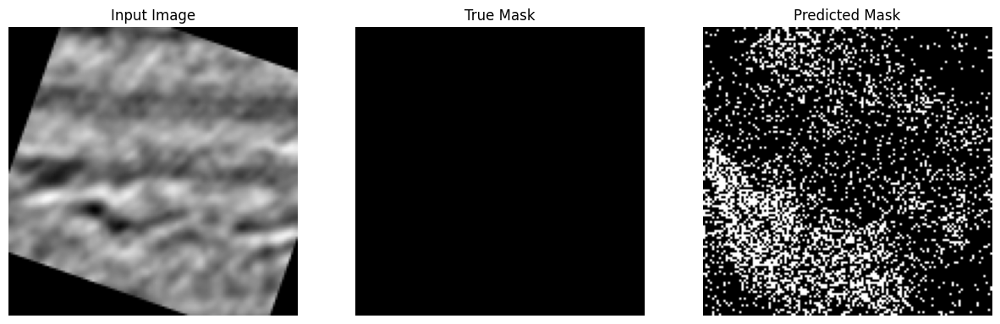

-------------------


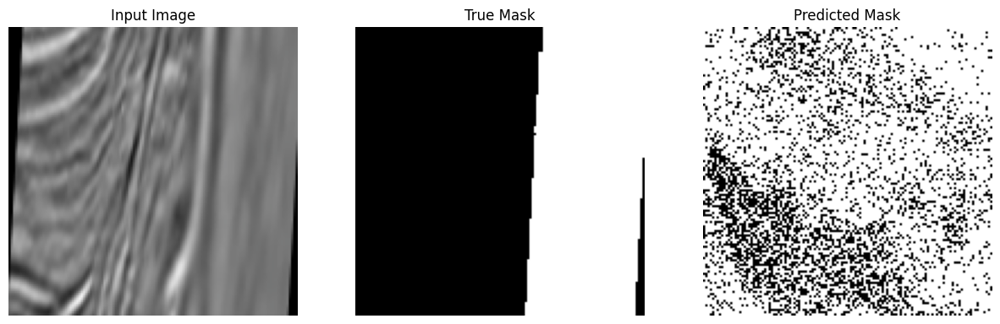

-------------------


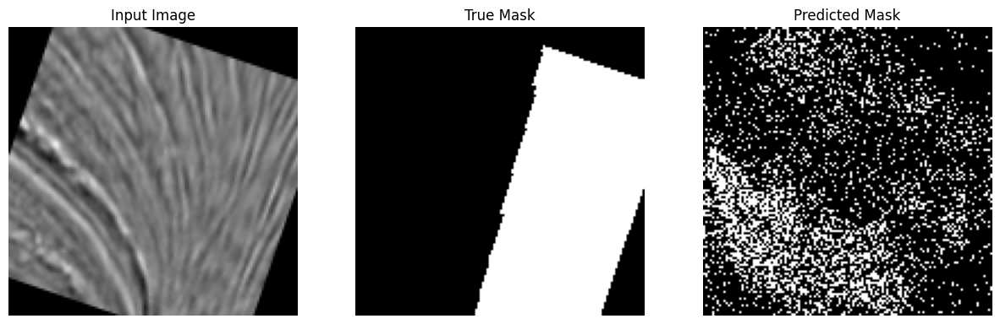

-------------------


In [ ]:
# we will display just a few examples
for idx, (img, mask) in enumerate(test_loader):
    img = img.to(device)
    mask = mask.to(device)

    with torch.no_grad():
        pred = torch.sigmoid(model(img))
        pred_mask = (pred > 0.5).float()

    # show images
    display_image_true_pred_mask(img[0], mask[0], pred_mask[0])

    # Wait for 2 seconds
    time.sleep(2)
    print("-------------------")
    # clear_output(wait=True)

    if idx == 100:
        break

### FCN versus Auto-Encoder (Encoder–Decoder)

I directly compared two segmentation approaches in my experiments:  

**Auto-Encoder (Encoder–Decoder Structure):**  
Variants using the encoder–decoder design (e.g., Variant 1) performed exceptionally well, achieving accuracy above 90% and a strong F1 score (~0.7670). This structure effectively captures both global context (via down-sampling) and fine spatial details (via up-sampling and skip connections), making it well-suited for segmentation tasks.  

**Fully Convolutional Network (FCN):**  
In contrast, the FCN variant (Variant 6) performed significantly worse, with accuracy dropping to ~60.18% and an F1 score of just ~0.2565. Without a hierarchical structure, it struggled to combine contextual information with fine-grained spatial details—both crucial for accurate pixel-level segmentation.  

**Conclusion:**  
The auto-encoder (encoder–decoder) structure is essential for effective semantic segmentation. It strikes a balance between capturing high-level context and preserving detailed localization, whereas an FCN that maintains constant resolution fails to achieve this.

# Conclusion and My Openion

I reached this conclusion after experimenting with all the different configurations suggested in the topic.  

To accurately answer the following questions, we must implement and test each approach—there’s no better way to evaluate their impact:  

1. Max Pooling  
2. Skip Connections  
3. FCN vs. Auto-Encoder  
4. Threshold Selection for Inference  

**Here is a simple summary of answers for the questions above:**  

1. **Max Pooling vs. Strided Convolution:**  
   Max pooling is more effective for down-sampling in U-Net, as it preserves critical features better than strided convolution.  

2. **Skip Connections:**  
   Skip connections are essential for merging multi-scale information. Removing them slightly reduces performance, and concatenation proves to be the best fusion method.  

3. **Auto-Encoder Structure vs. FCN:**  
   The encoder–decoder (auto-encoder) architecture significantly outperforms an FCN that maintains input resolution. Its ability to capture both global context and fine details makes it superior for segmentation tasks.  

4. **Threshold Selection for Inference:**  
   A fixed threshold (e.g., 0.5) provides a reasonable balance between precision and recall, but non-optimal thresholds can degrade performance. To achieve the best trade-off, precision and recall must be carefully tuned—either through threshold optimization or improved loss functions—based on specific task requirements.  